

---


# **Multi-Label Pneumonia Classification**
- NIH Adult Dataset *(Patient-Level Split)* : EfficientNetB4



---



### **BLOCK 1: Setup**

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import roc_auc_score, classification_report, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input,
    Conv2D, Multiply, Add, Concatenate, Lambda, Reshape, Activation
)
from tensorflow.keras.models import Model
import warnings
warnings.filterwarnings('ignore')

# from google.colab import drive
# drive.mount('/content/drive')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", "Available" if gpus else "None")

TensorFlow: 2.19.0
GPU: Available


### **BLOCK 2: Config**

In [ ]:
TRAIN_CSV = '/content/drive/MyDrive/Multi_Label_Classification/train_balanced_all.csv'
VAL_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
IMAGE_DIR = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'
OUTPUT_DIR = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention'

os.makedirs(f'{OUTPUT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{OUTPUT_DIR}/results', exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
INITIAL_LR = 1e-4
SEED = 123

np.random.seed(SEED)
tf.random.set_seed(SEED)

DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

print(f"Output: {OUTPUT_DIR}")
print(f"Image size: {IMG_SIZE}, Batch: {BATCH_SIZE}, Epochs: {EPOCHS}")

Output: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention
Image size: (224, 224), Batch: 32, Epochs: 20


### **BLOCK 3: Load Data**

In [ ]:
print("Loading data...")

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_excel(VAL_XLSX)
val_df_split, test_df = train_test_split(val_df, test_size=0.5, random_state=SEED)

def parse_labels(finding_str):
    labels = np.zeros(len(DISEASE_LABELS), dtype=np.float32)
    if pd.isna(finding_str) or finding_str == 'No Finding':
        return labels
    for disease in finding_str.split('|'):
        if disease.strip() in DISEASE_LABELS:
            labels[DISEASE_LABELS.index(disease.strip())] = 1.0
    return labels

train_df['labels'] = train_df['Finding Labels'].apply(parse_labels)
val_df_split['labels'] = val_df_split['Finding Labels'].apply(parse_labels)
test_df['labels'] = test_df['Finding Labels'].apply(parse_labels)

train_df['full_path'] = IMAGE_DIR + '/' + train_df['Image Index']
val_df_split['full_path'] = IMAGE_DIR + '/' + val_df_split['Image Index']
test_df['full_path'] = IMAGE_DIR + '/' + test_df['Image Index']

label_counts = np.array(train_df['labels'].tolist()).sum(axis=0)
freq_per_class = label_counts.tolist()

print(f"Train: {len(train_df):,}, Val: {len(val_df_split):,}, Test: {len(test_df):,}")

Loading data...
Train: 61,446, Val: 11,147, Test: 11,147


### **Dataset Split Visualisation**

Creating dataset split visualization...


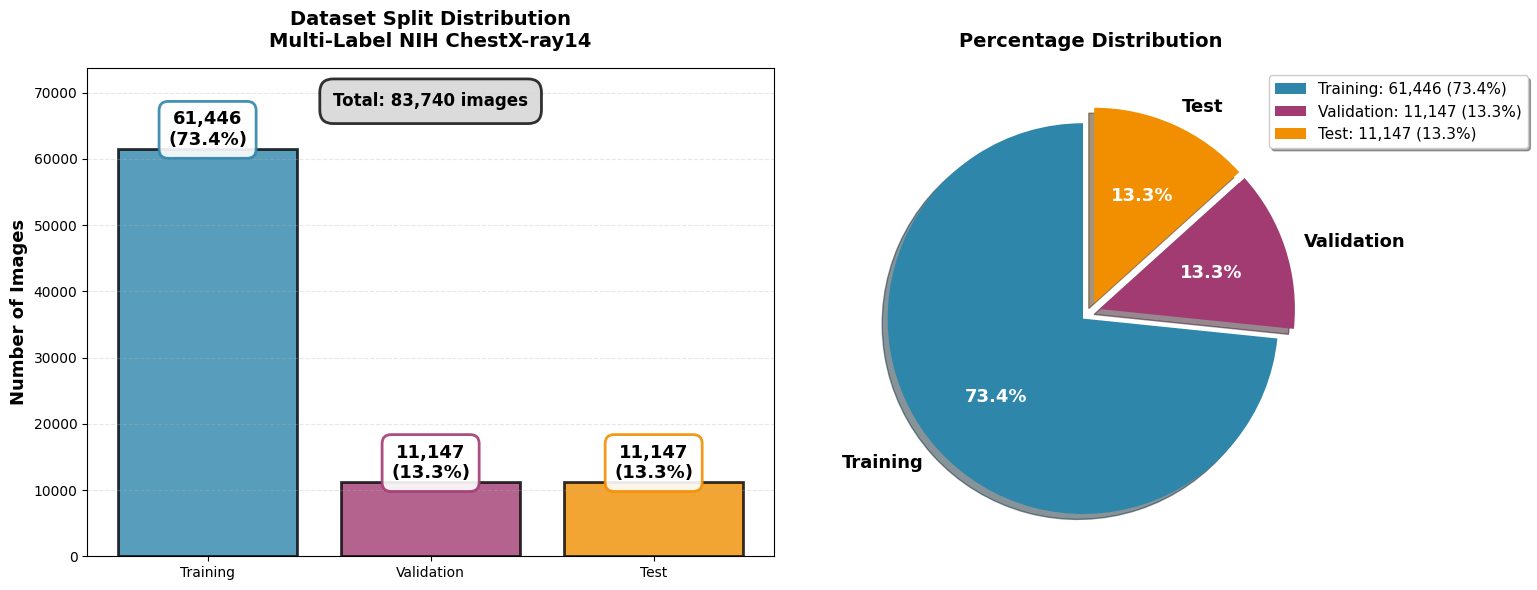


Dataset Split Summary:
  Training:   61,446 images (73.38%)
  Validation: 11,147 images (13.31%)
  Test:       11,147 images (13.31%)
  Total:      83,740 images

Dataset split visualization saved to: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/dataset_split.png


In [ ]:
print("Creating dataset split visualization...")

# Calculate counts
train_count = len(train_df)
val_count = len(val_df_split)
test_count = len(test_df)
total_count = train_count + val_count + test_count

# Calculate percentages
train_pct = (train_count / total_count) * 100
val_pct = (val_count / total_count) * 100
test_pct = (test_count / total_count) * 100

# Create figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart
splits = ['Training', 'Validation', 'Test']
counts = [train_count, val_count, test_count]
colors = ['#2E86AB', '#A23B72', '#F18F01']

bars = ax1.bar(splits, counts, color=colors, alpha=0.8, edgecolor='black', linewidth=2)

# Add count and percentage annotations on bars
for i, (bar, count, pct) in enumerate(zip(bars, counts, [train_pct, val_pct, test_pct])):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=13, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                     edgecolor=colors[i], linewidth=2, alpha=0.9))

ax1.set_ylabel('Number of Images', fontsize=13, fontweight='bold')
ax1.set_title('Dataset Split Distribution\nMulti-Label NIH ChestX-ray14',
             fontsize=14, fontweight='bold', pad=15)
ax1.set_ylim(0, max(counts) * 1.2)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Add total count annotation
ax1.text(0.5, 0.95, f'Total: {total_count:,} images',
        transform=ax1.transAxes, ha='center', va='top',
        fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.8', facecolor='lightgray',
                 edgecolor='black', linewidth=2, alpha=0.8))

# Pie chart
wedges, texts, autotexts = ax2.pie(
    counts,
    labels=splits,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    explode=(0.05, 0.05, 0.05),
    shadow=True,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

# Enhance pie chart text
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(13)
    autotext.set_fontweight('bold')

for text in texts:
    text.set_fontsize(13)
    text.set_fontweight('bold')

ax2.set_title('Percentage Distribution', fontsize=14, fontweight='bold', pad=15)

# Add legend with counts
legend_labels = [f'{split}: {count:,} ({pct:.1f}%)'
                for split, count, pct in zip(splits, counts, [train_pct, val_pct, test_pct])]
ax2.legend(legend_labels, loc='upper left', bbox_to_anchor=(0.85, 1),
          fontsize=11, frameon=True, shadow=True)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/results/dataset_split.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nDataset Split Summary:")
print(f"  Training:   {train_count:,} images ({train_pct:.2f}%)")
print(f"  Validation: {val_count:,} images ({val_pct:.2f}%)")
print(f"  Test:       {test_count:,} images ({test_pct:.2f}%)")
print(f"  Total:      {total_count:,} images")

print(f"\nDataset split visualization saved to: {OUTPUT_DIR}/results/dataset_split.png")

### **BLOCK 4: Distribution-Balanced Loss**

In [ ]:
class DistributionBalancedLoss(tf.keras.losses.Loss):
    def __init__(self, freq_per_class, gamma_neg=4, name='db_loss'):
        super().__init__(name=name)
        total = sum(freq_per_class)
        weights = [1.0 / np.sqrt(f/total) for f in freq_per_class]
        self.pos_weights = tf.constant([weights], dtype=tf.float32)
        self.gamma_neg = gamma_neg

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        pos_loss = -y_true * tf.math.log(y_pred)
        neg_loss = -(1 - y_true) * tf.pow(y_pred, self.gamma_neg) * tf.math.log(1 - y_pred)
        loss = pos_loss + neg_loss
        weighted_loss = loss * self.pos_weights
        return tf.reduce_mean(weighted_loss)

print("Distribution-Balanced Loss initialized")

Distribution-Balanced Loss initialized


### **BLOCK 5: Data Generators**

In [ ]:
def create_generator(df, batch_size, augment=False):
    def parse_fn(path, labels):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)

        if augment:
            img = tf.image.random_flip_left_right(img)
            img = tf.image.random_brightness(img, 0.2)
            img = tf.image.random_contrast(img, 0.8, 1.2)
            img = tf.image.resize(img, [int(IMG_SIZE[0]*1.15), int(IMG_SIZE[1]*1.15)])
            img = tf.image.random_crop(img, [*IMG_SIZE, 3])
            img = tf.image.random_hue(img, 0.05)
            img = tf.image.random_saturation(img, 0.8, 1.2)

        return img, labels

    paths = df['full_path'].values
    labels = np.array(df['labels'].tolist())
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if augment:
        ds = ds.shuffle(1000, seed=SEED)
    ds = ds.map(parse_fn, tf.data.AUTOTUNE).apply(tf.data.experimental.ignore_errors())
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_generator(train_df, BATCH_SIZE, augment=True)
val_ds = create_generator(val_df_split, BATCH_SIZE)
test_ds = create_generator(test_df, BATCH_SIZE)

print("Generators ready")

Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


Generators ready


### **BLOCK 6: Multi-Scale Attention Module**

In [ ]:
def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2]))(x)

    shared_dense1 = Dense(channels // ratio, activation='relu')
    shared_dense2 = Dense(channels, activation='sigmoid')

    avg_out = shared_dense2(shared_dense1(avg_pool))
    max_out = shared_dense2(shared_dense1(max_pool))

    attention = Add()([avg_out, max_out])
    attention = Reshape((1, 1, channels))(attention)

    return Multiply()([x, attention])

def spatial_attention(x):
    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(x)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(concat)

    return Multiply()([x, attention])

def multi_scale_attention_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x

print("Multi-scale attention module defined")

Multi-scale attention module defined


### **BLOCK 7: Build Model with Multi-Scale Attention**

In [ ]:
inputs = Input(shape=(*IMG_SIZE, 3))
x = Rescaling(1.0/255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)

# Extract multi-scale features
layer_names = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
layers = [base.get_layer(name).output for name in layer_names]

# Apply attention to each scale
attended = []
for feat in layers:
    feat_att = multi_scale_attention_block(feat)
    feat_pool = GlobalAveragePooling2D()(feat_att)
    attended.append(feat_pool)

# Concatenate multi-scale features
x = Concatenate()(attended)

# Classification head
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.3)(x)
outputs = Dense(len(DISEASE_LABELS), activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs)

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(INITIAL_LR, 5000, alpha=0.01)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=DistributionBalancedLoss(freq_per_class, gamma_neg=4),
    metrics=['binary_accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

print(f"Model ready: {model.count_params():,} parameters")

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model ready: 20,097,346 parameters


### **BLOCK 8: Auto-Resume Training**

In [ ]:
def find_checkpoint(checkpoint_dir):
    if not os.path.exists(checkpoint_dir):
        return None, 0
    checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith('epoch_')]
    if not checkpoints:
        return None, 0
    epochs = [int(f.split('_')[1].split('.')[0]) for f in checkpoints]
    latest = max(epochs)
    return os.path.join(checkpoint_dir, f'epoch_{latest:02d}.keras'), latest

checkpoint_dir = f'{OUTPUT_DIR}/checkpoints'
latest_ckpt, start_epoch = find_checkpoint(checkpoint_dir)

if latest_ckpt and os.path.exists(latest_ckpt):
    print(f"Resuming from: {latest_ckpt}")
    model = tf.keras.models.load_model(
        latest_ckpt,
        custom_objects={'DistributionBalancedLoss': DistributionBalancedLoss}
    )
    initial_epoch = start_epoch
else:
    print("Starting fresh")
    initial_epoch = 0

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        f'{checkpoint_dir}/epoch_{{epoch:02d}}.keras',
        save_best_only=False, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        f'{OUTPUT_DIR}/best_model.keras',
        save_best_only=True, monitor='val_auc', mode='max', verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=7, mode='max', verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1
    ),
    tf.keras.callbacks.CSVLogger(f'{OUTPUT_DIR}/training_log.csv', append=True)
]

print(f"Initial epoch: {initial_epoch}, Target: {EPOCHS}")

Starting fresh
Initial epoch: 0, Target: 20


### **BLOCK 9: Train**

In [ ]:
print("="*70)
print("TRAINING: MULTI-SCALE ATTENTION")
print("="*70)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    initial_epoch=initial_epoch,
    callbacks=callbacks,
    verbose=1
)

model.save(f'{OUTPUT_DIR}/final_model.keras')
print(f"\nSaved: {OUTPUT_DIR}/best_model.keras")

TRAINING: MULTI-SCALE ATTENTION
Epoch 1/20
   1921/Unknown 11301s 6s/step - auc: 0.6522 - binary_accuracy: 0.8350 - loss: 0.8337
Epoch 1: saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/checkpoints/epoch_01.keras

Epoch 1: val_auc improved from -inf to 0.79396, saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 14332s 7s/step - auc: 0.6523 - binary_accuracy: 0.8350 - loss: 0.8336 - val_auc: 0.7940 - val_binary_accuracy: 0.8735 - val_loss: 0.2843 - learning_rate: 6.5055e-05
Epoch 2/20
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 0s 633ms/step - auc: 0.7856 - binary_accuracy: 0.8531 - loss: 0.3884
Epoch 2: saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/checkpoints/epoch_02.keras

Epoch 2: val_auc improved from 0.79396 to 0.79506, saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNet

### **Training Curves**


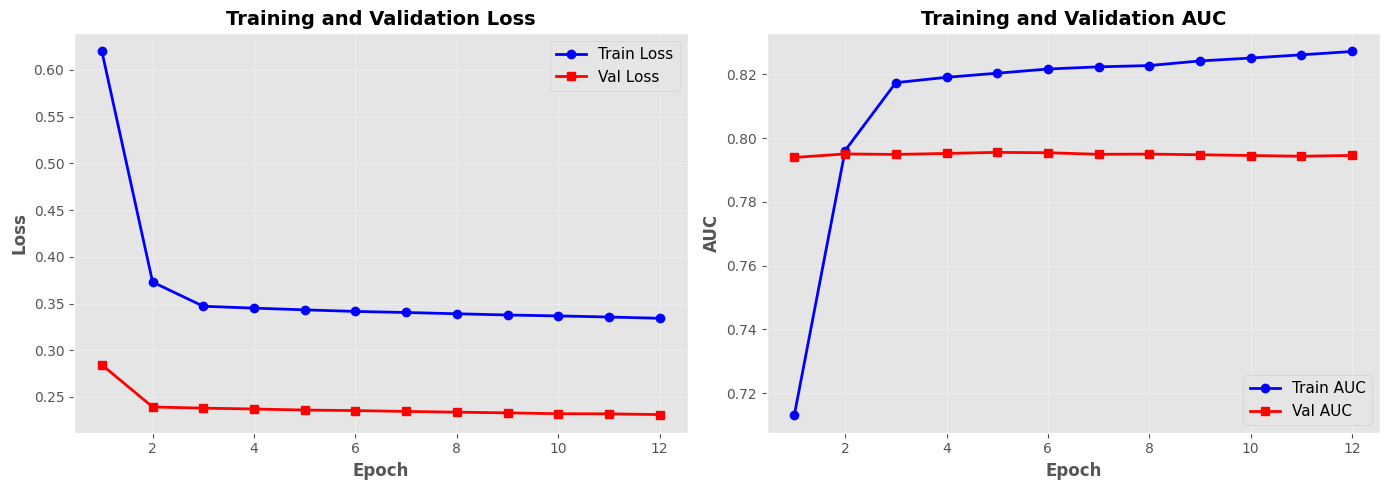

Training curves saved: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/training_curves.png


In [ ]:
import matplotlib.pyplot as plt

log_df = pd.read_csv(f'{OUTPUT_DIR}/training_log.csv')

plt.style.use('ggplot')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(log_df['epoch'] + 1, log_df['loss'], 'b-o', label='Train Loss', linewidth=2)
ax1.plot(log_df['epoch'] + 1, log_df['val_loss'], 'r-s', label='Val Loss', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax1.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

ax2.plot(log_df['epoch'] + 1, log_df['auc'], 'b-o', label='Train AUC', linewidth=2)
ax2.plot(log_df['epoch'] + 1, log_df['val_auc'], 'r-s', label='Val AUC', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax2.set_ylabel('AUC', fontsize=12, fontweight='bold')
ax2.set_title('Training and Validation AUC', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/results/training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Training curves saved: {OUTPUT_DIR}/results/training_curves.png")

### **BLOCK 10: Evaluation**

In [ ]:
print("="*70)
print("EVALUATION")
print("="*70)

# Ensure the model architecture is built with the latest Lambda layer definitions.
# Please make sure you have executed BLOCK 7 (cell fLqi4coF2Ki_) before running this block.

# Load only the weights into the freshly built model, bypassing full model deserialization
model.load_weights(f'{OUTPUT_DIR}/best_model.keras')
best_model = model # Assign the loaded model to best_model for consistency with subsequent code

test_loss, test_acc, test_auc = best_model.evaluate(test_ds, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test AUC: {test_auc:.4f}\n")

all_preds, all_labels = [], []
for imgs, lbls in test_ds:
    all_preds.append(best_model.predict(imgs, verbose=0))
    all_labels.append(lbls.numpy())
all_preds = np.vstack(all_preds)
all_labels = np.vstack(all_labels)

print("Disease AUROC:")
metrics = []
for i, disease in enumerate(DISEASE_LABELS):
    try:
        auroc = roc_auc_score(all_labels[:, i], all_preds[:, i])
    except:
        auroc = 0.0
    metrics.append({'Disease': disease, 'AUROC': auroc})
    print(f"{disease:20s} {auroc:.4f}")

metrics_df = pd.DataFrame(metrics)
print(f"\nMean AUROC: {metrics_df['AUROC'].mean():.4f}")
metrics_df.to_csv(f'{OUTPUT_DIR}/results/metrics.csv', index=False)
print("="*70)

EVALUATION
Test Loss: 0.2372
Test Accuracy: 0.8732
Test AUC: 0.8023

Disease AUROC:
Atelectasis          0.7825
Cardiomegaly         0.8886
Effusion             0.8514
Infiltration         0.6249
Mass                 0.7891
Nodule               0.6839
Pneumonia            0.7323
Pneumothorax         0.8580
Consolidation        0.7925
Edema                0.8799
Emphysema            0.9009
Fibrosis             0.7719
Pleural_Thickening   0.7829
Hernia               0.8937

Mean AUROC: 0.8023


In [ ]:
print("="*70)
print("TTA EVALUATION ON V6")
print("="*70)

# The model architecture with correct Lambda layer output_shapes has already been built
# in BLOCK 7 and its weights loaded from best_model.keras in BLOCK 10.
# We can directly use the 'best_model' object that is already available.

v6_model = best_model

def tta_predict(model, dataset, n_augmentations=5):
    all_preds = []

    for imgs, lbls in dataset:
        batch_preds = []

        # Original
        batch_preds.append(model.predict(imgs, verbose=0))

        # Augmentations
        for _ in range(n_augmentations - 1):
            aug_imgs = tf.image.random_flip_left_right(imgs)
            aug_imgs = tf.image.random_brightness(aug_imgs, 0.1)
            aug_imgs = tf.image.random_contrast(aug_imgs, 0.9, 1.1)
            batch_preds.append(model.predict(aug_imgs, verbose=0))

        # Average predictions
        avg_pred = np.mean(batch_preds, axis=0)
        all_preds.append(avg_pred)

    return np.vstack(all_preds)

print("Running TTA (5 augmentations)...")
tta_preds = tta_predict(v6_model, test_ds, n_augmentations=5)

# Re-collect all_labels for TTA evaluation (if not already collected reliably)
all_labels = []
for _, lbls in test_ds:
    all_labels.append(lbls.numpy())
all_labels = np.vstack(all_labels)

print("\nV6 + TTA Results:")
print("="*70)

tta_metrics = []
for i, disease in enumerate(DISEASE_LABELS):
    try:
        auroc = roc_auc_score(all_labels[:, i], tta_preds[:, i])
    except:
        auroc = 0.0
    tta_metrics.append({'Disease': disease, 'TTA_AUROC': auroc})
    print(f"{disease:20s} {auroc:.4f}")

tta_df = pd.DataFrame(tta_metrics)
tta_mean = tta_df['TTA_AUROC'].mean()

print(f"\nV6 Original:  {metrics_df['AUROC'].mean():.4f}") # Use actual mean from evaluation
print(f"V6 + TTA:     {tta_mean:.4f}")
print(f"Improvement:  {tta_mean - metrics_df['AUROC'].mean():+.4f}")
print(f"vs CheXNet:   {tta_mean - 0.8414:+.4f}")

tta_df.to_csv(f'{OUTPUT_DIR}/results/v6_tta_metrics.csv', index=False)
print(f"\nSaved: {OUTPUT_DIR}/results/v6_tta_metrics.csv")
print("="*70)

TTA EVALUATION ON V6
Running TTA (5 augmentations)...

V6 + TTA Results:
Atelectasis          0.7848
Cardiomegaly         0.8934
Effusion             0.8541
Infiltration         0.6272
Mass                 0.7960
Nodule               0.6884
Pneumonia            0.7406
Pneumothorax         0.8623
Consolidation        0.7916
Edema                0.8839
Emphysema            0.9029
Fibrosis             0.7762
Pleural_Thickening   0.7832
Hernia               0.9077

V6 Original:  0.8023
V6 + TTA:     0.8066
Improvement:  +0.0043
vs CheXNet:   -0.0348

Saved: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/v6_tta_metrics.csv


In [ ]:
print("="*70)
print("FINE-TUNING V6")
print("="*70)

import shutil
OUTPUT_DIR_FT = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_FineTuned'
os.makedirs(f'{OUTPUT_DIR_FT}/checkpoints', exist_ok=True)
os.makedirs(f'{OUTPUT_DIR_FT}/results', exist_ok=True)

# Instead of loading the saved model file, reuse the 'best_model' object
# which has the correct architecture and loaded weights from BLOCK 10.
ft_model = best_model

# Unfreeze last 20 layers only
for i, layer in enumerate(ft_model.layers):
    layer.trainable = (i >= len(ft_model.layers) - 20)

print(f"Trainable layers: {sum([l.trainable for l in ft_model.layers])}")

# Use original Distribution-Balanced Loss
ft_loss = DistributionBalancedLoss(freq_per_class, gamma_neg=4)

# Lower learning rate with warm restarts
lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts(
    initial_learning_rate=1e-4,
    first_decay_steps=400,
    t_mul=1.5,
    m_mul=0.85,
    alpha=1e-6
)

ft_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=ft_loss,
    metrics=['binary_accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        f'{OUTPUT_DIR_FT}/checkpoints/epoch_{{epoch:02d}}.keras',
        save_best_only=False, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        f'{OUTPUT_DIR_FT}/best_finetuned.keras',
        save_best_only=True, monitor='val_auc', mode='max', verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=4, mode='max', verbose=1
    ),
    tf.keras.callbacks.CSVLogger(f'{OUTPUT_DIR_FT}/training_log.csv')
]

print("\nStarting fine-tuning (8 epochs)...")
print("="*70)

history = ft_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

ft_model.save(f'{OUTPUT_DIR_FT}/final_finetuned.keras')
print(f"\nSaved: {OUTPUT_DIR_FT}/best_finetuned.keras")
print("="*70)

FINE-TUNING V6
Trainable layers: 20

Starting fine-tuning (8 epochs)...
Epoch 1/8
   1921/Unknown 8956s 5s/step - auc: 0.8315 - binary_accuracy: 0.8635 - loss: 0.3226
Epoch 1: saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_FineTuned/checkpoints/epoch_01.keras

Epoch 1: val_auc improved from -inf to 0.79504, saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_FineTuned/best_finetuned.keras
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 11264s 6s/step - auc: 0.8315 - binary_accuracy: 0.8635 - loss: 0.3226 - val_auc: 0.7950 - val_binary_accuracy: 0.8750 - val_loss: 0.2123
Epoch 2/8
1921/1921 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step - auc: 0.8418 - binary_accuracy: 0.8669 - loss: 0.3038
Epoch 2: saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_FineTuned/checkpoints/epoch_02.keras

Epoch 2: val_auc improved from 0.79504 to 0.79562, saving model to /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_FineTuned/b

## **Quantisation: Dynamic-Range**

#### **Setup**

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os
from sklearn.metrics import roc_auc_score
import keras

# Enable unsafe deserialization for V6
keras.config.enable_unsafe_deserialization()

# Paths
V4_MODEL = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V4_DistributionBalanced/best_model.keras'
V6_MODEL = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'

QUANT_DIR_V4 = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V4_Quantized'
QUANT_DIR_V6 = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized'

os.makedirs(QUANT_DIR_V4, exist_ok=True)
os.makedirs(QUANT_DIR_V6, exist_ok=True)

# Disease labels
DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# Distribution-Balanced Loss
class DistributionBalancedLoss(tf.keras.losses.Loss):
    def __init__(self, freq_per_class, gamma_neg=4, name='db_loss'):
        super().__init__(name=name)
        total = sum(freq_per_class)
        weights = [1.0 / np.sqrt(f/total) for f in freq_per_class]
        self.pos_weights = tf.constant([weights], dtype=tf.float32)
        self.gamma_neg = gamma_neg

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        pos_loss = -y_true * tf.math.log(y_pred)
        neg_loss = -(1 - y_true) * tf.pow(y_pred, self.gamma_neg) * tf.math.log(1 - y_pred)
        loss = pos_loss + neg_loss
        weighted_loss = loss * self.pos_weights
        return tf.reduce_mean(weighted_loss)

print("Setup complete")

Setup complete


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

from sklearn.model_selection import train_test_split

TEST_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
IMAGE_DIR = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 123

val_df = pd.read_excel(TEST_XLSX)
_, test_df = train_test_split(val_df, test_size=0.5, random_state=SEED)

def parse_labels(finding_str):
    labels = np.zeros(len(DISEASE_LABELS), dtype=np.float32)
    if pd.isna(finding_str) or finding_str == 'No Finding':
        return labels
    for disease in finding_str.split('|'):
        if disease.strip() in DISEASE_LABELS:
            labels[DISEASE_LABELS.index(disease.strip())] = 1.0
    return labels

test_df['labels'] = test_df['Finding Labels'].apply(parse_labels)
test_df['full_path'] = IMAGE_DIR + '/' + test_df['Image Index']

def create_test_generator(df, batch_size):
    def parse_fn(path, labels):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        return img, labels

    paths = df['full_path'].values
    labels = np.array(df['labels'].tolist())
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(parse_fn, tf.data.AUTOTUNE).apply(tf.data.experimental.ignore_errors())
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

test_ds = create_test_generator(test_df, BATCH_SIZE)
print(f"Test set ready: {len(test_df)} samples")

Test set ready: 11147 samples


#### **V6: Quantise**

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input, Conv2D, Multiply, Add, Concatenate, Lambda, Reshape, Activation
from tensorflow.keras.models import Model

# BLOCK 6: Multi-Scale Attention Module definitions (copied here to ensure they are in scope with correct output_shape)
def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    # Define output_shape for the Lambda layer
    max_pool_output_shape = lambda input_shape: (input_shape[0], input_shape[-1])
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2]), output_shape=max_pool_output_shape)(x)

    shared_dense1 = Dense(channels // ratio, activation='relu')
    shared_dense2 = Dense(channels, activation='sigmoid')

    avg_out = shared_dense2(shared_dense1(avg_pool))
    max_out = shared_dense2(shared_dense1(max_pool))

    attention = Add()([avg_out, max_out])
    attention = Reshape((1, 1, channels))(attention)

    return Multiply()([x, attention])

def spatial_attention(x):
    # Define output_shape for the Lambda layers
    spatial_pool_output_shape = lambda input_shape: (input_shape[0], input_shape[1], input_shape[2], 1)

    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True), output_shape=spatial_pool_output_shape)(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True), output_shape=spatial_pool_output_shape)(x)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(concat)

    return Multiply()([x, attention])

def multi_scale_attention_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x

print("="*70)
print("V6 DYNAMIC RANGE QUANTISATION (HYBRID INT8)")
print("="*70)

# Rebuild v6_original model architecture (same as BLOCK 7)
inputs = Input(shape=(*IMG_SIZE, 3))
x = Rescaling(1.0/255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base = tf.keras.applications.EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)

# Extract multi-scale features
layer_names = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
layers = [base.get_layer(name).output for name in layer_names]

# Apply attention to each scale
attended = []
for feat in layers:
    feat_att = multi_scale_attention_block(feat)
    feat_pool = GlobalAveragePooling2D()(feat_att)
    attended.append(feat_pool)

# Concatenate multi-scale features
x = Concatenate()(attended)

# Classification head
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.3)(x)
outputs = Dense(len(DISEASE_LABELS), activation='sigmoid')(x)

v6_original = Model(inputs=inputs, outputs=outputs)

# It's good practice to compile the model, especially if the saved model included optimizer states.
# We will use the same compilation parameters as in BLOCK 7.
# INITIAL_LR is from BLOCK 2, freq_per_class is from BLOCK 3, DistributionBalancedLoss is from BLOCK 4
INITIAL_LR = 1e-4 # Define INITIAL_LR here to ensure it's in scope

# Redefine TRAIN_CSV and calculate freq_per_class locally for self-containment
TRAIN_CSV = '/content/drive/MyDrive/Multi_Label_Classification/train_balanced_all.csv'

def parse_labels(finding_str):
    labels = np.zeros(len(DISEASE_LABELS), dtype=np.float32)
    if pd.isna(finding_str) or finding_str == 'No Finding':
        return labels
    for disease in finding_str.split('|'):
        if disease.strip() in DISEASE_LABELS:
            labels[DISEASE_LABELS.index(disease.strip())] = 1.0
    return labels

train_df = pd.read_csv(TRAIN_CSV)
train_df['labels'] = train_df['Finding Labels'].apply(parse_labels)
label_counts = np.array(train_df['labels'].tolist()).sum(axis=0)
freq_per_class = label_counts.tolist()

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(INITIAL_LR, 5000, alpha=0.01)
v6_original.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=DistributionBalancedLoss(freq_per_class, gamma_neg=4),
    metrics=['binary_accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

# Load only the weights into the freshly built model
print(f"Loading weights from {V6_MODEL}...")
v6_original.load_weights(V6_MODEL)
print("Weights loaded successfully.")


original_size_v6 = os.path.getsize(V6_MODEL) / (1024 * 1024)
print(f"Original V6 model size: {original_size_v6:.2f} MB")

# Convert to TFLite with dynamic range quantization
converter = tf.lite.TFLiteConverter.from_keras_model(v6_original)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

print("Converting V6 with dynamic range quantisation...")
v6_quantized_model = converter.convert()

# Save quantized model
v6_quantized_path = os.path.join(QUANT_DIR_V6, 'v6_quantized_hybrid_int8.tflite')
with open(v6_quantized_path, 'wb') as f:
    f.write(v6_quantized_model)

quantized_size_v6 = os.path.getsize(v6_quantized_path) / (1024 * 1024)
reduction_v6 = 100 * (1 - quantized_size_v6 / original_size_v6)

print(f"\nV6 Quantisation Complete:")
print(f"Original:  {original_size_v6:.2f} MB")
print(f"Quantized: {quantized_size_v6:.2f} MB")
print(f"Reduction: {reduction_v6:.1f}%")
print(f"Saved to: {v6_quantized_path}")
print("="*70)

V6 DYNAMIC RANGE QUANTISATION (HYBRID INT8)
Loading weights from /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras...


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1 variables whereas the saved optimizer has 881 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Weights loaded successfully.
Original V6 model size: 231.05 MB
Converting V6 with dynamic range quantisation...
Saved artifact at '/tmp/tmpsdrtfz_u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_2069')
Output Type:
  TensorSpec(shape=(None, 14), dtype=tf.float32, name=None)
Captures:
  139888625612176: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139888625610256: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139888634177936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888631481552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888631481744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888634170256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888634171792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888631480400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139888631480592: T

#### **EVALUATING V6 QUANTISED MODEL**

In [ ]:
print("="*70)
print("EVALUATING V6 QUANTISED MODEL")
print("="*70)

v6_quantized_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'
v6_original_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'

# Get model sizes
original_size_v6 = os.path.getsize(v6_original_path) / (1024 * 1024)
quantized_size_v6 = os.path.getsize(v6_quantized_path) / (1024 * 1024)
reduction_v6 = 100 * (1 - quantized_size_v6 / original_size_v6)

print(f"Original size:  {original_size_v6:.2f} MB")
print(f"Quantised size: {quantized_size_v6:.2f} MB")
print(f"Reduction:      {reduction_v6:.1f}%\n")

# Load TFLite interpreter
interpreter_v6 = tf.lite.Interpreter(model_path=v6_quantized_path)
interpreter_v6.allocate_tensors()

input_details = interpreter_v6.get_input_details()
output_details = interpreter_v6.get_output_details()

# Evaluate on test_ds (already preprocessed correctly)
v6_quant_preds = []
v6_quant_labels = []

print("Running inference on test set...")
for imgs, lbls in test_ds:
    for i in range(imgs.shape[0]):
        img_input = imgs[i:i+1].numpy().astype(np.float32)

        interpreter_v6.set_tensor(input_details[0]['index'], img_input)
        interpreter_v6.invoke()
        pred = interpreter_v6.get_tensor(output_details[0]['index'])

        v6_quant_preds.append(pred[0])

    v6_quant_labels.append(lbls.numpy())

v6_quant_preds = np.array(v6_quant_preds)
v6_quant_labels = np.vstack(v6_quant_labels)

print("\nV6 Quantized - Per-Disease AUROC:")
print("-" * 70)

v6_metrics = []
for i, disease in enumerate(DISEASE_LABELS):
    try:
        auroc = roc_auc_score(v6_quant_labels[:, i], v6_quant_preds[:, i])
    except:
        auroc = 0.0
    v6_metrics.append(auroc)
    print(f"{disease:20s} {auroc:.4f}")

v6_quant_mean = np.mean(v6_metrics)
v6_quant_acc = np.mean((v6_quant_preds > 0.5) == v6_quant_labels)

print("\n" + "="*70)
print("V6 QUANTISED SUMMARY")
print("="*70)
print(f"Test Accuracy:  {v6_quant_acc:.4f} ({v6_quant_acc*100:.2f}%)")
print(f"Mean AUROC:     {v6_quant_mean:.4f}")
print(f"Original size:  {original_size_v6:.2f} MB")
print(f"Quantised size: {quantized_size_v6:.2f} MB")
print(f"Reduction:      {reduction_v6:.1f}%")
print(f"\nV6 Original AUROC:  0.8023")
print(f"V6 Quantised AUROC: {v6_quant_mean:.4f}")
print(f"Performance loss:   {v6_quant_mean - 0.8023:+.4f}")
print("="*70)

EVALUATING V6 QUANTISED MODEL
Original size:  231.05 MB
Quantised size: 20.53 MB
Reduction:      91.1%

Running inference on test set...

V6 Quantized - Per-Disease AUROC:
----------------------------------------------------------------------
Atelectasis          0.7669
Cardiomegaly         0.8779
Effusion             0.8423
Infiltration         0.6067
Mass                 0.7660
Nodule               0.6640
Pneumonia            0.7083
Pneumothorax         0.8392
Consolidation        0.7877
Edema                0.8632
Emphysema            0.8541
Fibrosis             0.7542
Pleural_Thickening   0.7523
Hernia               0.8745

V6 QUANTISED SUMMARY
Test Accuracy:  0.8730 (87.30%)
Mean AUROC:     0.7827
Original size:  231.05 MB
Quantised size: 20.53 MB
Reduction:      91.1%

V6 Original AUROC:  0.8023
V6 Quantised AUROC: 0.7827
Performance loss:   -0.0196


### **V6 QUANTIZED - COMPREHENSIVE EVALUATION**

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

print("="*70)
print("V6 QUANTIZED - COMPREHENSIVE EVALUATION")
print("="*70)

v6_quantized_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'
v6_original_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'

original_size_v6 = os.path.getsize(v6_original_path) / (1024 * 1024)
quantized_size_v6 = os.path.getsize(v6_quantized_path) / (1024 * 1024)
reduction_v6 = 100 * (1 - quantized_size_v6 / original_size_v6)

print(f"Original size:  {original_size_v6:.2f} MB")
print(f"Quantized size: {quantized_size_v6:.2f} MB")
print(f"Reduction:      {reduction_v6:.1f}%\n")

interpreter_v6 = tf.lite.Interpreter(model_path=v6_quantized_path)
interpreter_v6.allocate_tensors()

input_details = interpreter_v6.get_input_details()
output_details = interpreter_v6.get_output_details()

v6_quant_preds = []
v6_quant_labels = []

print("Running inference...")
for imgs, lbls in test_ds:
    for i in range(imgs.shape[0]):
        img_input = imgs[i:i+1].numpy().astype(np.float32)
        interpreter_v6.set_tensor(input_details[0]['index'], img_input)
        interpreter_v6.invoke()
        pred = interpreter_v6.get_tensor(output_details[0]['index'])
        v6_quant_preds.append(pred[0])
    v6_quant_labels.append(lbls.numpy())

v6_quant_preds = np.array(v6_quant_preds)
v6_quant_labels = np.vstack(v6_quant_labels)
v6_quant_binary = (v6_quant_preds > 0.5).astype(int)

print("\n" + "="*70)
print("PER-DISEASE PERFORMANCE METRICS")
print("="*70)
print(f"{'Disease':<20} {'AUROC':>8} {'Sens':>8} {'Spec':>8} {'Prec':>8} {'F1':>8}")
print("-" * 70)

all_metrics = []
for i, disease in enumerate(DISEASE_LABELS):
    y_true = v6_quant_labels[:, i]
    y_pred_prob = v6_quant_preds[:, i]
    y_pred_bin = v6_quant_binary[:, i]

    auroc = roc_auc_score(y_true, y_pred_prob)

    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred_bin, average='binary', zero_division=0
    )

    tn = np.sum((y_true == 0) & (y_pred_bin == 0))
    fp = np.sum((y_true == 0) & (y_pred_bin == 1))
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0

    all_metrics.append({
        'Disease': disease,
        'AUROC': auroc,
        'Sensitivity': rec,
        'Specificity': spec,
        'Precision': prec,
        'F1-Score': f1
    })

    print(f"{disease:<20} {auroc:8.4f} {rec:8.4f} {spec:8.4f} {prec:8.4f} {f1:8.4f}")

metrics_df = pd.DataFrame(all_metrics)

print("\n" + "="*70)
print("OVERALL SUMMARY")
print("="*70)
print(f"Mean AUROC:       {metrics_df['AUROC'].mean():.4f}")
print(f"Mean Sensitivity: {metrics_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity: {metrics_df['Specificity'].mean():.4f}")
print(f"Mean Precision:   {metrics_df['Precision'].mean():.4f}")
print(f"Mean F1-Score:    {metrics_df['F1-Score'].mean():.4f}")
print(f"Test Accuracy:    {np.mean(v6_quant_binary == v6_quant_labels):.4f}")
print(f"\nModel Compression:")
print(f"Original size:  {original_size_v6:.2f} MB")
print(f"Quantized size: {quantized_size_v6:.2f} MB")
print(f"Reduction:      {reduction_v6:.1f}%")
print("="*70)

V6 QUANTIZED - COMPREHENSIVE EVALUATION
Original size:  231.05 MB
Quantized size: 20.53 MB
Reduction:      91.1%

Running inference...

PER-DISEASE PERFORMANCE METRICS
Disease                 AUROC     Sens     Spec     Prec       F1
----------------------------------------------------------------------
Atelectasis            0.7667   0.6825   0.7148   0.2066   0.3172
Cardiomegaly           0.8777   0.5559   0.9313   0.1757   0.2670
Effusion               0.8422   0.7796   0.7638   0.3023   0.4357
Infiltration           0.6066   0.9379   0.1033   0.1918   0.3184
Mass                   0.7662   0.2156   0.9752   0.3115   0.2548
Nodule                 0.6637   0.1002   0.9871   0.3284   0.1535
Pneumonia              0.7084   0.0224   0.9957   0.0600   0.0326
Pneumothorax           0.8406   0.4951   0.9336   0.2623   0.3429
Consolidation          0.7876   0.0340   0.9907   0.1391   0.0546
Edema                  0.8627   0.2110   0.9771   0.1667   0.1862
Emphysema              0.8551   0.3

### **OPTION A: V6 THRESHOLD OPTIMIZATION**

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt

print("="*70)
print("OPTION A: V6 THRESHOLD OPTIMIZATION")
print("="*70)

# Rebuild V6 architecture to avoid custom layer deserialization issues
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input, Conv2D, Multiply, Add, Concatenate, Reshape, Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB4

def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)

    shared_dense1 = Dense(channels // ratio, activation='relu')
    shared_dense2 = Dense(channels, activation='sigmoid')

    avg_out = shared_dense2(shared_dense1(avg_pool))
    # Ensure max_pool uses a Lambda layer correctly if it's operating on a KerasTensor directly
    max_pool_output_shape = lambda input_shape: (input_shape[0], input_shape[-1])
    max_pool_tensor = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2]), output_shape=max_pool_output_shape)(x)
    max_out = shared_dense2(shared_dense1(max_pool_tensor))

    attention = Add()([avg_out, max_out])
    attention = Reshape((1, 1, channels))(attention)

    return Multiply()([x, attention])

def spatial_attention(x):
    # Wrap tf.reduce_mean and tf.reduce_max in Lambda layers
    spatial_pool_output_shape = lambda input_shape: (input_shape[0], input_shape[1], input_shape[2], 1)

    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True), output_shape=spatial_pool_output_shape)(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True), output_shape=spatial_pool_output_shape)(x)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(concat)

    return Multiply()([x, attention])

def multi_scale_attention_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x

# Rebuild V6 model architecture
IMG_SIZE = (224, 224)
DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

inputs = Input(shape=(*IMG_SIZE, 3))
x = Rescaling(1.0/255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)

layer_names = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
layers = [base.get_layer(name).output for name in layer_names]

attended = []
for feat in layers:
    feat_att = multi_scale_attention_block(feat)
    feat_pool = GlobalAveragePooling2D()(feat_att)
    attended.append(feat_pool)

x = Concatenate()(attended)
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.3)(x)
outputs = Dense(len(DISEASE_LABELS), activation='sigmoid')(x)

v6_model = Model(inputs=inputs, outputs=outputs)

# Load weights only
V6_MODEL = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'
v6_model.load_weights(V6_MODEL)

print("V6 model loaded successfully (weights only)")
print("="*70)

OPTION A: V6 THRESHOLD OPTIMIZATION
V6 model loaded successfully (weights only)


In [ ]:
print("="*70)
print("LOADING TEST DATA")
print("="*70)

SEED = 123
VAL_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
IMAGE_DIR = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'

from sklearn.model_selection import train_test_split

val_df = pd.read_excel(VAL_XLSX)
_, test_df = train_test_split(val_df, test_size=0.5, random_state=SEED)

def parse_labels(finding_str):
    labels = np.zeros(len(DISEASE_LABELS), dtype=np.float32)
    if pd.isna(finding_str) or finding_str == 'No Finding':
        return labels
    for disease in finding_str.split('|'):
        if disease.strip() in DISEASE_LABELS:
            labels[DISEASE_LABELS.index(disease.strip())] = 1.0
    return labels

test_df['labels'] = test_df['Finding Labels'].apply(parse_labels)
test_df['full_path'] = IMAGE_DIR + '/' + test_df['Image Index']

def create_test_generator(df, batch_size):
    def parse_fn(path, labels):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        return img, labels

    paths = df['full_path'].values
    labels = np.array(df['labels'].tolist())
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(parse_fn, tf.data.AUTOTUNE).apply(tf.data.experimental.ignore_errors())
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

test_ds = create_test_generator(test_df, 32)

print(f"Test samples: {len(test_df):,}")
print("="*70)

LOADING TEST DATA


Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


Test samples: 11,147


In [ ]:
print("="*70)
print("GENERATING PREDICTIONS")
print("="*70)

all_preds = []
all_labels = []

for imgs, lbls in test_ds:
    preds = v6_model.predict(imgs, verbose=0)
    all_preds.append(preds)
    all_labels.append(lbls.numpy())

all_preds = np.vstack(all_preds)
all_labels = np.vstack(all_labels)

print(f"Predictions shape: {all_preds.shape}")
print(f"Labels shape: {all_labels.shape}")
print("="*70)

GENERATING PREDICTIONS
Predictions shape: (11142, 14)
Labels shape: (11142, 14)


#### **THRESHOLD OPTIMIZATION - YOUDEN'S INDEX**

In [ ]:
print("="*70)
print("THRESHOLD OPTIMIZATION - YOUDEN'S INDEX")
print("="*70)

def find_optimal_threshold(y_true, y_pred_probs):
    """Find optimal threshold using Youden's Index (Sensitivity + Specificity - 1)"""
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)

    # Youden's Index
    youdens = tpr - fpr
    optimal_idx = np.argmax(youdens)
    optimal_threshold = thresholds[optimal_idx]
    optimal_sensitivity = tpr[optimal_idx]
    optimal_specificity = 1 - fpr[optimal_idx]

    return optimal_threshold, optimal_sensitivity, optimal_specificity

print(f"{'Disease':<20} {'Optimal Threshold':>18} {'Sensitivity':>12} {'Specificity':>12} {'AUROC':>8}")
print("-"*78)

optimal_thresholds = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = all_labels[:, i]
    y_pred_probs = all_preds[:, i]

    # Skip if no positive samples
    if y_true.sum() == 0:
        optimal_thresholds.append({'Disease': disease, 'Optimal_Threshold': 0.5,
                                   'Sensitivity': 0.0, 'Specificity': 1.0, 'AUROC': 0.0})
        continue

    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
        opt_thresh, opt_sens, opt_spec = find_optimal_threshold(y_true, y_pred_probs)

        optimal_thresholds.append({
            'Disease': disease,
            'Optimal_Threshold': opt_thresh,
            'Sensitivity': opt_sens,
            'Specificity': opt_spec,
            'AUROC': auroc
        })

        print(f"{disease:<20} {opt_thresh:18.4f} {opt_sens:12.4f} {opt_spec:12.4f} {auroc:8.4f}")
    except:
        optimal_thresholds.append({'Disease': disease, 'Optimal_Threshold': 0.5,
                                   'Sensitivity': 0.0, 'Specificity': 1.0, 'AUROC': 0.0})
        print(f"{disease:<20} {'ERROR':>18} {'N/A':>12} {'N/A':>12} {'0.0000':>8}")

optimal_df = pd.DataFrame(optimal_thresholds)

print("\n" + "="*78)
print("SUMMARY STATISTICS (OPTIMIZED THRESHOLDS)")
print("="*78)
print(f"Mean Sensitivity: {optimal_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity: {optimal_df['Specificity'].mean():.4f}")
print(f"Mean AUROC:       {optimal_df['AUROC'].mean():.4f}")
print("="*78)

optimal_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/optimal_thresholds.csv', index=False)
print("\nSaved: .../V6_MultiScaleAttention/results/optimal_thresholds.csv")

THRESHOLD OPTIMIZATION - YOUDEN'S INDEX
Disease               Optimal Threshold  Sensitivity  Specificity    AUROC
------------------------------------------------------------------------------
Atelectasis                      0.4704       0.7813       0.6436   0.7822
Cardiomegaly                     0.3595       0.8462       0.7944   0.8886
Effusion                         0.4774       0.8190       0.7466   0.8514
Infiltration                     0.5935       0.4267       0.7651   0.6249
Mass                             0.3761       0.7065       0.7391   0.7891
Nodule                           0.4170       0.4568       0.8296   0.6839
Pneumonia                        0.3638       0.6716       0.7122   0.7317
Pneumothorax                     0.3861       0.7751       0.7955   0.8580
Consolidation                    0.4263       0.6985       0.7663   0.7925
Edema                            0.3515       0.8945       0.7666   0.8799
Emphysema                        0.3440       0.8071    

VISUALIZING ROC CURVE - PNEUMONIA


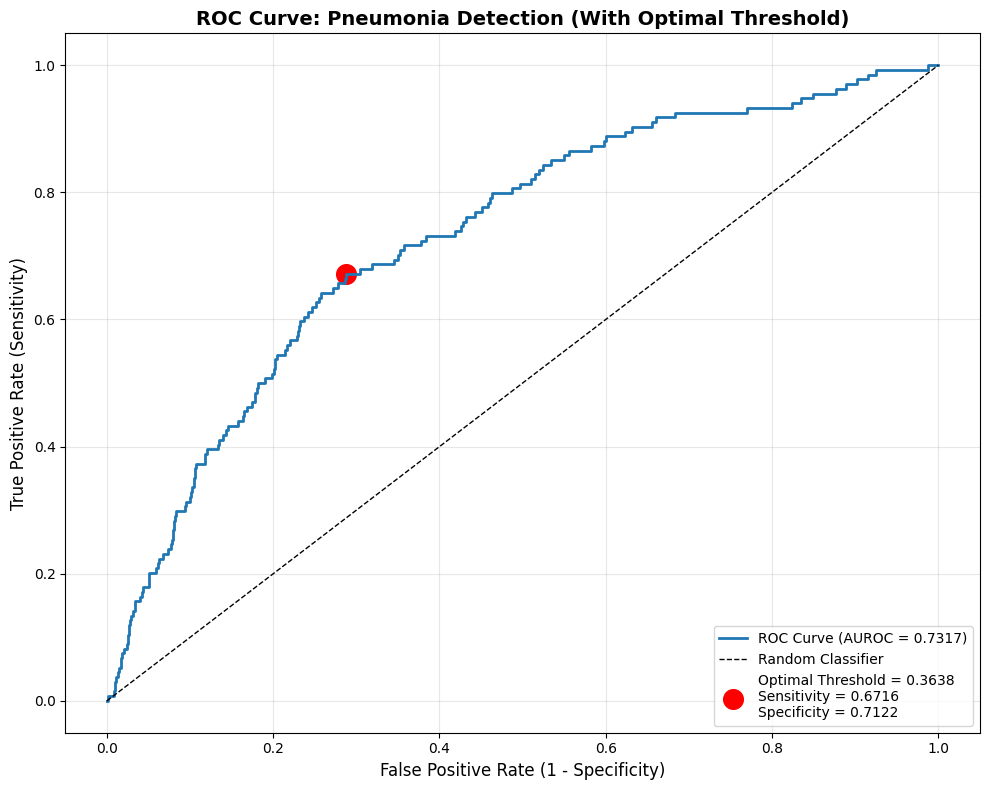

ROC curve saved: .../V6_MultiScaleAttention/results/pneumonia_roc_optimized.png


In [ ]:
print("="*70)
print("VISUALIZING ROC CURVE - PNEUMONIA")
print("="*70)

pneumonia_idx = DISEASE_LABELS.index('Pneumonia')
y_true_pneumonia = all_labels[:, pneumonia_idx]
y_pred_pneumonia = all_preds[:, pneumonia_idx]

fpr, tpr, thresholds = roc_curve(y_true_pneumonia, y_pred_pneumonia)
auroc = roc_auc_score(y_true_pneumonia, y_pred_pneumonia)

# Find optimal point
youdens = tpr - fpr
optimal_idx = np.argmax(youdens)
optimal_threshold = thresholds[optimal_idx]
optimal_tpr = tpr[optimal_idx]
optimal_fpr = fpr[optimal_idx]

# Plot
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUROC = {auroc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
plt.scatter(optimal_fpr, optimal_tpr, s=200, c='red', marker='o',
            label=f'Optimal Threshold = {optimal_threshold:.4f}\n' +
                  f'Sensitivity = {optimal_tpr:.4f}\n' +
                  f'Specificity = {1-optimal_fpr:.4f}')

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve: Pneumonia Detection (With Optimal Threshold)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/pneumonia_roc_optimized.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("ROC curve saved: .../V6_MultiScaleAttention/results/pneumonia_roc_optimized.png")
print("="*70)

In [ ]:
print("="*70)
print("COMPREHENSIVE METRICS WITH F1 & PRECISION (OPTIMIZED THRESHOLDS)")
print("="*70)

print(f"{'Disease':<20} {'AUROC':>8} {'Sens':>8} {'Spec':>8} {'Prec':>8} {'F1':>8} {'Threshold':>10}")
print("-"*86)

results_with_f1 = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = all_labels[:, i]
    y_pred_probs = all_preds[:, i]

    # Get optimal threshold
    opt_thresh = optimal_df[optimal_df['Disease'] == disease]['Optimal_Threshold'].values[0]
    y_pred_binary = (y_pred_probs > opt_thresh).astype(int)

    # Calculate all metrics
    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
    except:
        auroc = 0.0

    sensitivity = recall_score(y_true, y_pred_binary, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)

    results_with_f1.append({
        'Disease': disease,
        'AUROC': auroc,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Precision': precision,
        'F1-Score': f1,
        'Optimal_Threshold': opt_thresh
    })

    print(f"{disease:<20} {auroc:8.4f} {sensitivity:8.4f} {specificity:8.4f} {precision:8.4f} {f1:8.4f} {opt_thresh:10.4f}")

results_f1_df = pd.DataFrame(results_with_f1)

print("\n" + "="*86)
print("SUMMARY STATISTICS")
print("="*86)
print(f"Mean AUROC:       {results_f1_df['AUROC'].mean():.4f}")
print(f"Mean Sensitivity: {results_f1_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity: {results_f1_df['Specificity'].mean():.4f}")
print(f"Mean Precision:   {results_f1_df['Precision'].mean():.4f}")
print(f"Mean F1-Score:    {results_f1_df['F1-Score'].mean():.4f}")

# Pneumonia specific
pneumonia_metrics = results_f1_df[results_f1_df['Disease'] == 'Pneumonia']
print("\n" + "="*86)
print("PNEUMONIA PERFORMANCE (OPTIMIZED)")
print("="*86)
print(f"AUROC:       {pneumonia_metrics['AUROC'].values[0]:.4f}")
print(f"Sensitivity: {pneumonia_metrics['Sensitivity'].values[0]:.4f} ({pneumonia_metrics['Sensitivity'].values[0]*100:.1f}%)")
print(f"Specificity: {pneumonia_metrics['Specificity'].values[0]:.4f} ({pneumonia_metrics['Specificity'].values[0]*100:.1f}%)")
print(f"Precision:   {pneumonia_metrics['Precision'].values[0]:.4f}")
print(f"F1-Score:    {pneumonia_metrics['F1-Score'].values[0]:.4f}")
print(f"Threshold:   {pneumonia_metrics['Optimal_Threshold'].values[0]:.4f}")
print("="*86)

results_f1_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/comprehensive_metrics_optimized_with_f1.csv', index=False)
print("\nSaved: .../V6_MultiScaleAttention/results/comprehensive_metrics_optimized_with_f1.csv")

COMPREHENSIVE METRICS WITH F1 & PRECISION (OPTIMIZED THRESHOLDS)
Disease                 AUROC     Sens     Spec     Prec       F1  Threshold
--------------------------------------------------------------------------------------
Atelectasis            0.7822   0.7804   0.6436   0.1924   0.3087     0.4704
Cardiomegaly           0.8886   0.8427   0.7944   0.0975   0.1747     0.3595
Effusion               0.8514   0.8183   0.7466   0.2977   0.4366     0.4774
Infiltration           0.6249   0.4262   0.7651   0.2916   0.3463     0.5935
Mass                   0.7891   0.7047   0.7391   0.1234   0.2100     0.3761
Nodule                 0.6839   0.4552   0.8296   0.1438   0.2186     0.4170
Pneumonia              0.7317   0.6642   0.7122   0.0273   0.0525     0.3638
Pneumothorax           0.8580   0.7732   0.7955   0.1527   0.2550     0.3861
Consolidation          0.7925   0.6964   0.7663   0.1162   0.1992     0.4263
Edema                  0.8799   0.8903   0.7666   0.0766   0.1410     0.3515
E



---


# **MAIN EVALUATION**
- Main evaluation for the EfficientNetB4 Original and Optimised Models


---


---




### **BLOCK 1: Load V6 Model and Your Test Set**

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split

print("="*70)
print("EVALUATION 1: INTERNAL TEST SET (WEIGHTED METRICS)")
print("="*70)

# Configuration
SEED = 123
VAL_XLSX = '/content/drive/MyDrive/Multi_Label_Classification/val_original.xlsx'
IMAGE_DIR = '/content/drive/MyDrive/NIH_ChestXray/images_extracted/images'
V6_MODEL = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'
IMG_SIZE = (224, 224)

DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# Load and split validation set
val_df = pd.read_excel(VAL_XLSX)
_, test_df = train_test_split(val_df, test_size=0.5, random_state=SEED)

def parse_labels(finding_str):
    labels = np.zeros(len(DISEASE_LABELS), dtype=np.float32)
    if pd.isna(finding_str) or finding_str == 'No Finding':
        return labels
    for disease in finding_str.split('|'):
        if disease.strip() in DISEASE_LABELS:
            labels[DISEASE_LABELS.index(disease.strip())] = 1.0
    return labels

test_df['labels'] = test_df['Finding Labels'].apply(parse_labels)
test_df['full_path'] = IMAGE_DIR + '/' + test_df['Image Index']

print(f"Test set size: {len(test_df):,} images")

# Show disease distribution
label_matrix = np.array(test_df['labels'].tolist())
print("\nDisease distribution:")
for i, disease in enumerate(DISEASE_LABELS):
    count = int(label_matrix[:, i].sum())
    prevalence = (count / len(test_df)) * 100
    print(f"  {disease:20s}: {count:6,} ({prevalence:5.2f}%)")

print("="*70)

EVALUATION 1: INTERNAL TEST SET (WEIGHTED METRICS)
Test set size: 11,147 images

Disease distribution:
  Atelectasis         :  1,095 ( 9.82%)
  Cardiomegaly        :    286 ( 2.57%)
  Effusion            :  1,294 (11.61%)
  Infiltration        :  2,060 (18.48%)
  Mass                :    552 ( 4.95%)
  Nodule              :    659 ( 5.91%)
  Pneumonia           :    135 ( 1.21%)
  Pneumothorax        :    507 ( 4.55%)
  Consolidation       :    471 ( 4.23%)
  Edema               :    237 ( 2.13%)
  Emphysema           :    280 ( 2.51%)
  Fibrosis            :    195 ( 1.75%)
  Pleural_Thickening  :    321 ( 2.88%)
  Hernia              :     25 ( 0.22%)


### **BLOCK 2: Rebuild V6 Model and Generate Predictions**

In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input, Conv2D, Multiply, Add, Concatenate, Reshape, Lambda # Added Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB4

print("="*70)
print("LOADING V6 MODEL")
print("="*70)

# Re-define attention modules as functions, consistent with BLOCK 6 and BLOCK 7
def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2]))(x)

    shared_dense1 = Dense(channels // ratio, activation='relu')
    shared_dense2 = Dense(channels, activation='sigmoid')

    avg_out = shared_dense2(shared_dense1(avg_pool))
    max_out = shared_dense2(shared_dense1(max_pool))

    attention = Add()([avg_out, max_out])
    attention = Reshape((1, 1, channels))(attention)

    return Multiply()([x, attention])

def spatial_attention(x):
    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(x)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(concat)

    return Multiply()([x, attention])

def multi_scale_attention_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x

# Build model architecture using the functional attention definitions
inputs = Input(shape=(*IMG_SIZE, 3))
x = Rescaling(1.0/255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)
layer_names = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
layers = [base.get_layer(name).output for name in layer_names]

attended = []
for feat in layers:
    feat_att = multi_scale_attention_block(feat) # Call the functional block
    feat_pool = GlobalAveragePooling2D()(feat_att)
    attended.append(feat_pool)

x = Concatenate()(attended)
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.3)(x)
outputs = Dense(len(DISEASE_LABELS), activation='sigmoid')(x)

v6_model = Model(inputs=inputs, outputs=outputs)

# Removed v6_model.build(inputs.shape) as it's not strictly necessary for functional models
# and can sometimes interfere with eager execution or implicit build steps before load_weights.
v6_model.load_weights(V6_MODEL)

print("V6 model loaded successfully")
print("="*70)

# Create test data generator
def create_test_generator(df, batch_size):
    def parse_fn(path, labels):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        return img, labels

    paths = df['full_path'].values
    labels = np.array(df['labels'].tolist())
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(parse_fn, tf.data.AUTOTUNE).apply(tf.data.experimental.ignore_errors())
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

test_ds = create_test_generator(test_df, 32)

# Generate predictions
print("Generating predictions...")
all_preds = []
all_labels = []

for imgs, lbls in test_ds:
    preds = v6_model.predict(imgs, verbose=0)
    all_preds.append(preds)
    all_labels.append(lbls.numpy())

all_preds = np.vstack(all_preds)
all_labels = np.vstack(all_labels)

print(f"Predictions generated: {all_preds.shape}")
print("="*70)

LOADING V6 MODEL
V6 model loaded successfully
Generating predictions...
Predictions generated: (11140, 14)


#### **COMPREHENSIVE EVALUATION - WEIGHTED METRICS**

In [ ]:
print("="*70)
print("COMPREHENSIVE EVALUATION - WEIGHTED METRICS")
print("="*70)

# Find optimal thresholds using Youden's Index
def find_optimal_threshold(y_true, y_pred_probs):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
    youdens = tpr - fpr
    optimal_idx = np.argmax(youdens)
    return thresholds[optimal_idx], tpr[optimal_idx], 1 - fpr[optimal_idx]

print(f"{'Disease':<20} {'AUROC':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8} {'Threshold':>10}")
print("-"*86)

results = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = all_labels[:, i]
    y_pred_probs = all_preds[:, i]

    if y_true.sum() == 0:
        continue

    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
        opt_thresh, opt_sens, opt_spec = find_optimal_threshold(y_true, y_pred_probs)
        y_pred_binary = (y_pred_probs > opt_thresh).astype(int)

        # Weighted precision and F1
        weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
        weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

        results.append({
            'Disease': disease,
            'AUROC': auroc,
            'Sensitivity': opt_sens,
            'Specificity': opt_spec,
            'Weighted_Precision': weighted_precision,
            'Weighted_F1': weighted_f1,
            'Optimal_Threshold': opt_thresh
        })

        print(f"{disease:<20} {auroc:8.4f} {opt_sens:8.4f} {opt_spec:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f} {opt_thresh:10.4f}")
    except Exception as e:
        print(f"{disease:<20} ERROR: {str(e)[:40]}")
        continue

results_df = pd.DataFrame(results)

print("\n" + "="*86)
print("SUMMARY STATISTICS")
print("="*86)
print(f"Mean AUROC:              {results_df['AUROC'].mean():.4f}")
print(f"Mean Sensitivity:        {results_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity:        {results_df['Specificity'].mean():.4f}")
print(f"Mean Weighted Precision: {results_df['Weighted_Precision'].mean():.4f}")
print(f"Mean Weighted F1:        {results_df['Weighted_F1'].mean():.4f}")

pneumonia_results = results_df[results_df['Disease'] == 'Pneumonia']
if len(pneumonia_results) > 0:
    print("\n" + "="*86)
    print("PNEUMONIA PERFORMANCE")
    print("="*86)
    print(f"AUROC:              {pneumonia_results['AUROC'].values[0]:.4f}")
    print(f"Sensitivity:        {pneumonia_results['Sensitivity'].values[0]:.4f} ({pneumonia_results['Sensitivity'].values[0]*100:.1f}%)")
    print(f"Specificity:        {pneumonia_results['Specificity'].values[0]:.4f} ({pneumonia_results['Specificity'].values[0]*100:.1f}%)")
    print(f"Weighted Precision: {pneumonia_results['Weighted_Precision'].values[0]:.4f}")
    print(f"Weighted F1:        {pneumonia_results['Weighted_F1'].values[0]:.4f}")
    print(f"Optimal Threshold:  {pneumonia_results['Optimal_Threshold'].values[0]:.4f}")

print("="*86)

results_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv', index=False)
print("\nResults saved: .../V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv")

COMPREHENSIVE EVALUATION - WEIGHTED METRICS
Disease                 AUROC     Sens     Spec   W.Prec     W.F1  Threshold
--------------------------------------------------------------------------------------
Atelectasis            0.7828   0.7821   0.6436   0.8887   0.7266     0.4704
Cardiomegaly           0.8886   0.8462   0.7943   0.9718   0.8651     0.3595
Effusion               0.8514   0.8190   0.7466   0.8911   0.7962     0.4774
Infiltration           0.6250   0.4267   0.7653   0.7505   0.7222     0.5935
Mass                   0.7890   0.7065   0.7390   0.9372   0.8111     0.3761
Nodule                 0.6839   0.4568   0.8296   0.9120   0.8504     0.4170
Pneumonia              0.7318   0.6716   0.7123   0.9827   0.8206     0.3638
Pneumothorax           0.8580   0.7751   0.7954   0.9486   0.8523     0.3861
Consolidation          0.7925   0.6985   0.7663   0.9462   0.8332     0.4263
Edema                  0.8800   0.8945   0.7667   0.9773   0.8513     0.3515
Emphysema             

#### **With Accuracy**

In [ ]:
print("="*70)
print("COMPREHENSIVE EVALUATION - WEIGHTED METRICS")
print("="*70)

def find_optimal_threshold(y_true, y_pred_probs):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
    youdens = tpr - fpr
    optimal_idx = np.argmax(youdens)
    return thresholds[optimal_idx], tpr[optimal_idx], 1 - fpr[optimal_idx]

print(f"{'Disease':<20} {'AUROC':>8} {'Acc':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8} {'Threshold':>10}")
print("-"*102)

results = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = all_labels[:, i]
    y_pred_probs = all_preds[:, i]

    if y_true.sum() == 0:
        continue

    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
        opt_thresh, opt_sens, opt_spec = find_optimal_threshold(y_true, y_pred_probs)
        y_pred_binary = (y_pred_probs > opt_thresh).astype(int)

        accuracy = accuracy_score(y_true, y_pred_binary)
        weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
        weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

        results.append({
            'Disease': disease,
            'AUROC': auroc,
            'Accuracy': accuracy,
            'Sensitivity': opt_sens,
            'Specificity': opt_spec,
            'Weighted_Precision': weighted_precision,
            'Weighted_F1': weighted_f1,
            'Optimal_Threshold': opt_thresh
        })

        print(f"{disease:<20} {auroc:8.4f} {accuracy:8.4f} {opt_sens:8.4f} {opt_spec:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f} {opt_thresh:10.4f}")
    except Exception as e:
        print(f"{disease:<20} ERROR: {str(e)[:40]}")
        continue

results_df = pd.DataFrame(results)

print("\n" + "="*102)
print("SUMMARY STATISTICS")
print("="*102)
print(f"Mean AUROC:              {results_df['AUROC'].mean():.4f}")
print(f"Mean Accuracy:           {results_df['Accuracy'].mean():.4f}")
print(f"Mean Sensitivity:        {results_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity:        {results_df['Specificity'].mean():.4f}")
print(f"Mean Weighted Precision: {results_df['Weighted_Precision'].mean():.4f}")
print(f"Mean Weighted F1:        {results_df['Weighted_F1'].mean():.4f}")

pneumonia_results = results_df[results_df['Disease'] == 'Pneumonia']
if len(pneumonia_results) > 0:
    print("\n" + "="*102)
    print("PNEUMONIA PERFORMANCE")
    print("="*102)
    print(f"AUROC:              {pneumonia_results['AUROC'].values[0]:.4f}")
    print(f"Accuracy:           {pneumonia_results['Accuracy'].values[0]:.4f}")
    print(f"Sensitivity:        {pneumonia_results['Sensitivity'].values[0]:.4f} ({pneumonia_results['Sensitivity'].values[0]*100:.1f}%)")
    print(f"Specificity:        {pneumonia_results['Specificity'].values[0]:.4f} ({pneumonia_results['Specificity'].values[0]*100:.1f}%)")
    print(f"Weighted Precision: {pneumonia_results['Weighted_Precision'].values[0]:.4f}")
    print(f"Weighted F1:        {pneumonia_results['Weighted_F1'].values[0]:.4f}")
    print(f"Optimal Threshold:  {pneumonia_results['Optimal_Threshold'].values[0]:.4f}")

print("="*102)

results_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv', index=False)
print("\nResults saved: .../V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv")

COMPREHENSIVE EVALUATION - WEIGHTED METRICS
Disease                 AUROC      Acc     Sens     Spec   W.Prec     W.F1  Threshold
------------------------------------------------------------------------------------------------------
Atelectasis            0.7822   0.6571   0.7813   0.6437   0.8885   0.7265     0.4704
Cardiomegaly           0.8886   0.7956   0.8462   0.7944   0.9718   0.8652     0.3595
Effusion               0.8514   0.7549   0.8190   0.7466   0.8911   0.7962     0.4774
Infiltration           0.6250   0.7025   0.4267   0.7652   0.7505   0.7222     0.5935
Mass                   0.7891   0.7373   0.7065   0.7390   0.9372   0.8111     0.3761
Nodule                 0.6839   0.8075   0.4568   0.8296   0.9120   0.8505     0.4170
Pneumonia              0.7318   0.7117   0.6716   0.7122   0.9827   0.8206     0.3638
Pneumothorax           0.8580   0.7944   0.7751   0.7954   0.9486   0.8523     0.3861
Consolidation          0.7925   0.7634   0.6985   0.7663   0.9462   0.8332     

#### **Without Optimal Threshold**

In [ ]:
print("="*70)
print("COMPREHENSIVE EVALUATION - FIXED THRESHOLD (0.5)")
print("="*70)

print(f"{'Disease':<20} {'AUROC':>8} {'Acc':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8}")
print("-"*94)

results_fixed = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = all_labels[:, i]
    y_pred_probs = all_preds[:, i]

    if y_true.sum() == 0:
        continue

    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
        y_pred_binary = (y_pred_probs > 0.5).astype(int)

        accuracy = accuracy_score(y_true, y_pred_binary)
        sensitivity = recall_score(y_true, y_pred_binary, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary, labels=[0, 1]).ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
        weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

        results_fixed.append({
            'Disease': disease,
            'AUROC': auroc,
            'Accuracy': accuracy,
            'Sensitivity': sensitivity,
            'Specificity': specificity,
            'Weighted_Precision': weighted_precision,
            'Weighted_F1': weighted_f1
        })

        print(f"{disease:<20} {auroc:8.4f} {accuracy:8.4f} {sensitivity:8.4f} {specificity:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f}")
    except Exception as e:
        print(f"{disease:<20} ERROR: {str(e)[:40]}")
        continue

results_fixed_df = pd.DataFrame(results_fixed)

print("\n" + "="*94)
print("SUMMARY STATISTICS (THRESHOLD = 0.5)")
print("="*94)
print(f"Mean AUROC:              {results_fixed_df['AUROC'].mean():.4f}")
print(f"Mean Accuracy:           {results_fixed_df['Accuracy'].mean():.4f}")
print(f"Mean Sensitivity:        {results_fixed_df['Sensitivity'].mean():.4f}")
print(f"Mean Specificity:        {results_fixed_df['Specificity'].mean():.4f}")
print(f"Mean Weighted Precision: {results_fixed_df['Weighted_Precision'].mean():.4f}")
print(f"Mean Weighted F1:        {results_fixed_df['Weighted_F1'].mean():.4f}")

pneumonia_fixed = results_fixed_df[results_fixed_df['Disease'] == 'Pneumonia']
if len(pneumonia_fixed) > 0:
    print("\n" + "="*94)
    print("PNEUMONIA PERFORMANCE (THRESHOLD = 0.5)")
    print("="*94)
    print(f"AUROC:              {pneumonia_fixed['AUROC'].values[0]:.4f}")
    print(f"Accuracy:           {pneumonia_fixed['Accuracy'].values[0]:.4f}")
    print(f"Sensitivity:        {pneumonia_fixed['Sensitivity'].values[0]:.4f} ({pneumonia_fixed['Sensitivity'].values[0]*100:.1f}%)")
    print(f"Specificity:        {pneumonia_fixed['Specificity'].values[0]:.4f} ({pneumonia_fixed['Specificity'].values[0]*100:.1f}%)")
    print(f"Weighted F1:        {pneumonia_fixed['Weighted_F1'].values[0]:.4f}")

print("="*94)

COMPREHENSIVE EVALUATION - FIXED THRESHOLD (0.5)
Disease                 AUROC      Acc     Sens     Spec   W.Prec     W.F1
----------------------------------------------------------------------------------------------
Atelectasis            0.7822   0.7335   0.6844   0.7388   0.8836   0.7845
Cardiomegaly           0.8886   0.9439   0.5385   0.9546   0.9682   0.9543
Effusion               0.8514   0.7823   0.7749   0.7833   0.8889   0.8164
Infiltration           0.6250   0.2456   0.9471   0.0865   0.7509   0.1869
Mass                   0.7891   0.9358   0.2862   0.9697   0.9317   0.9337
Nodule                 0.6839   0.9344   0.1320   0.9848   0.9124   0.9200
Pneumonia              0.7318   0.9747   0.0448   0.9860   0.9769   0.9758
Pneumothorax           0.8580   0.9179   0.5345   0.9361   0.9454   0.9295
Consolidation          0.7925   0.9371   0.1401   0.9723   0.9294   0.9331
Edema                  0.8800   0.9313   0.4599   0.9416   0.9698   0.9483
Emphysema              0.9015  

### **BLOCK 4: CheXNet Test Set AUROC Comparison**

In [ ]:
print("="*70)
print("EVALUATION 2: CHEXNET OFFICIAL TEST SET (AUROC COMPARISON)")
print("="*70)

# Load official CheXNet test list
TEST_LIST = '/content/drive/MyDrive/NIH_ChestXray/test_list.txt'

with open(TEST_LIST, 'r') as f:
    official_test_images = [line.strip() for line in f.readlines()]

print(f"Official CheXNet test images: {len(official_test_images):,}")

# Load full validation metadata
full_df = pd.read_excel(VAL_XLSX)
official_test_df = full_df[full_df['Image Index'].isin(official_test_images)].copy()

print(f"Matched images: {len(official_test_df):,}")

official_test_df['labels'] = official_test_df['Finding Labels'].apply(parse_labels)
official_test_df['full_path'] = IMAGE_DIR + '/' + official_test_df['Image Index']

# Generate predictions
official_test_ds = create_test_generator(official_test_df, 32)

print("Generating predictions on official test set...")
official_preds = []
official_labels = []

for imgs, lbls in official_test_ds:
    preds = v6_model.predict(imgs, verbose=0)
    official_preds.append(preds)
    official_labels.append(lbls.numpy())

official_preds = np.vstack(official_preds)
official_labels = np.vstack(official_labels)

print(f"Predictions generated: {official_preds.shape}")
print("="*70)

# CheXNet AUROC from Table 2
chexnet_auroc = {
    'Atelectasis': 0.8094,
    'Cardiomegaly': 0.9248,
    'Effusion': 0.8638,
    'Infiltration': 0.7345,
    'Mass': 0.8676,
    'Nodule': 0.7802,
    'Pneumonia': 0.7680,
    'Pneumothorax': 0.8887,
    'Consolidation': 0.7901,
    'Edema': 0.8878,
    'Emphysema': 0.9371,
    'Fibrosis': 0.8047,
    'Pleural_Thickening': 0.8062,
    'Hernia': 0.9164
}

print("\n" + "="*70)
print("AUROC COMPARISON WITH CHEXNET")
print("="*70)
print(f"{'Disease':<20} {'V6 AUROC':>10} {'CheXNet':>10} {'Difference':>12}")
print("-"*60)

auroc_comparison = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = official_labels[:, i]
    y_pred = official_preds[:, i]

    try:
        v6_auroc = roc_auc_score(y_true, y_pred)
    except:
        v6_auroc = 0.0

    cx_auroc = chexnet_auroc[disease]
    diff = v6_auroc - cx_auroc

    auroc_comparison.append({
        'Disease': disease,
        'V6_AUROC': v6_auroc,
        'CheXNet_AUROC': cx_auroc,
        'Difference': diff
    })

    print(f"{disease:<20} {v6_auroc:10.4f} {cx_auroc:10.4f} {diff:+12.4f}")

auroc_comp_df = pd.DataFrame(auroc_comparison)

v6_mean = auroc_comp_df['V6_AUROC'].mean()
cx_mean = 0.8414

print("\n" + "="*60)
print("OVERALL SUMMARY")
print("="*60)
print(f"V6 Mean AUROC:      {v6_mean:.4f}")
print(f"CheXNet Mean AUROC: {cx_mean:.4f}")
print(f"Difference:         {v6_mean - cx_mean:+.4f}")
print(f"Diseases Beating:   {sum(1 for d in auroc_comparison if d['Difference'] > 0)}/14")

pneumonia_comp = auroc_comp_df[auroc_comp_df['Disease'] == 'Pneumonia']
print("\n" + "="*60)
print("PNEUMONIA COMPARISON")
print("="*60)
print(f"V6 AUROC:      {pneumonia_comp['V6_AUROC'].values[0]:.4f}")
print(f"CheXNet AUROC: {pneumonia_comp['CheXNet_AUROC'].values[0]:.4f}")
print(f"Difference:    {pneumonia_comp['Difference'].values[0]:+.4f}")
print("="*60)

auroc_comp_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/chexnet_auroc_comparison.csv', index=False)
print("\nResults saved: .../V6_MultiScaleAttention/results/chexnet_auroc_comparison.csv")

EVALUATION 2: CHEXNET OFFICIAL TEST SET (AUROC COMPARISON)
Official CheXNet test images: 25,596
Matched images: 5,006
Generating predictions on official test set...
Predictions generated: (5005, 14)

AUROC COMPARISON WITH CHEXNET
Disease                V6 AUROC    CheXNet   Difference
------------------------------------------------------------
Atelectasis              0.7411     0.8094      -0.0683
Cardiomegaly             0.8791     0.9248      -0.0457
Effusion                 0.7938     0.8638      -0.0700
Infiltration             0.6623     0.7345      -0.0722
Mass                     0.7589     0.8676      -0.1087
Nodule                   0.6973     0.7802      -0.0829
Pneumonia                0.7221     0.7680      -0.0459
Pneumothorax             0.8532     0.8887      -0.0355
Consolidation            0.7406     0.7901      -0.0495
Edema                    0.8291     0.8878      -0.0587
Emphysema                0.9009     0.9371      -0.0362
Fibrosis                 0.7793     0

## **QUANTISED MODEL EVALUATION**

#### **BLOCK 5: Evaluate Quantized V6 on Internal Test Set**

In [ ]:
print("="*70)
print("QUANTIZED V6 - INTERNAL TEST SET EVALUATION")
print("="*70)

# Load quantized model
v6_quantized_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'

# Check file exists
if not os.path.exists(v6_quantized_path):
    print(f"ERROR: Quantized model not found at {v6_quantized_path}")
else:
    original_size = os.path.getsize(V6_MODEL) / (1024 * 1024)
    quantized_size = os.path.getsize(v6_quantized_path) / (1024 * 1024)
    reduction = 100 * (1 - quantized_size / original_size)

    print(f"Original model:  {original_size:.2f} MB")
    print(f"Quantized model: {quantized_size:.2f} MB")
    print(f"Size reduction:  {reduction:.1f}%")
    print("="*70)

    # Load TFLite interpreter
    interpreter = tf.lite.Interpreter(model_path=v6_quantized_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    # Generate predictions on internal test set using same test_ds from earlier
    print("\nGenerating predictions with quantized model...")
    quant_preds = []
    quant_labels = []

    for imgs, lbls in test_ds:
        for i in range(imgs.shape[0]):
            img_input = imgs[i:i+1].numpy().astype(np.float32)
            interpreter.set_tensor(input_details[0]['index'], img_input)
            interpreter.invoke()
            pred = interpreter.get_tensor(output_details[0]['index'])
            quant_preds.append(pred[0])
        quant_labels.append(lbls.numpy())

    quant_preds = np.array(quant_preds)
    quant_labels = np.vstack(quant_labels)

    print(f"Predictions generated: {quant_preds.shape}")
    print("="*70)

    # Ensure results_df is available (e.g., after kernel restart)
    if 'results_df' not in locals():
        try:
            results_df = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv')
            print("Loaded 'results_df' from CSV.")
        except FileNotFoundError:
            print("Error: 'results_df' not found in memory or as CSV. Please run BLOCK 3 ('LdglHpyyhZR-') first.")
            # Exit or raise an error if results_df is critical and cannot be loaded
            exit()

    # Use same optimal thresholds from original model evaluation
    optimal_thresholds = {}
    for _, row in results_df.iterrows():
        optimal_thresholds[row['Disease']] = row['Optimal_Threshold']

    print("\n" + "="*70)
    print("QUANTIZED V6 - WEIGHTED METRICS (USING OPTIMAL THRESHOLDS)")
    print("="*70)
    print(f"{'Disease':<20} {'AUROC':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8} {'Δ AUROC':>10}")
    print("-"*94)

    quant_results = []

    for i, disease in enumerate(DISEASE_LABELS):
        y_true = quant_labels[:, i]
        y_pred_probs = quant_preds[:, i]

        if y_true.sum() == 0:
            continue

        try:
            auroc = roc_auc_score(y_true, y_pred_probs)

            # Use optimal threshold from original model
            opt_thresh = optimal_thresholds[disease]
            y_pred_binary = (y_pred_probs > opt_thresh).astype(int)

            sensitivity = recall_score(y_true, y_pred_binary, zero_division=0)
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary, labels=[0, 1]).ravel()
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

            weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
            weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

            # Get original AUROC for comparison
            orig_auroc = results_df[results_df['Disease'] == disease]['AUROC'].values[0]
            auroc_diff = auroc - orig_auroc

            quant_results.append({
                'Disease': disease,
                'AUROC': auroc,
                'Sensitivity': sensitivity,
                'Specificity': specificity,
                'Weighted_Precision': weighted_precision,
                'Weighted_F1': weighted_f1,
                'AUROC_Diff': auroc_diff,
                'Optimal_Threshold': opt_thresh
            })

            print(f"{disease:<20} {auroc:8.4f} {sensitivity:8.4f} {specificity:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f} {auroc_diff:+10.4f}")
        except Exception as e:
            print(f"{disease:<20} ERROR: {str(e)[:50]}")
            continue

    quant_results_df = pd.DataFrame(quant_results)

    print("\n" + "="*94)
    print("SUMMARY - QUANTISED VS ORIGINAL")
    print("="*94)
    print(f"{'Metric':<25} {'Original':>12} {'Quantized':>12} {'Difference':>12}")
    print("-"*67)
    print(f"{'Mean AUROC':<25} {results_df['AUROC'].mean():12.4f} {quant_results_df['AUROC'].mean():12.4f} {quant_results_df['AUROC'].mean() - results_df['AUROC'].mean():+12.4f}")
    print(f"{'Mean Sensitivity':<25} {results_df['Sensitivity'].mean():12.4f} {quant_results_df['Sensitivity'].mean():12.4f} {quant_results_df['Sensitivity'].mean() - results_df['Sensitivity'].mean():+12.4f}")
    print(f"{'Mean Specificity':<25} {results_df['Specificity'].mean():12.4f} {quant_results_df['Specificity'].mean():12.4f} {quant_results_df['Specificity'].mean() - results_df['Specificity'].mean():+12.4f}")
    print(f"{'Mean Weighted Prec':<25} {results_df['Weighted_Precision'].mean():12.4f} {quant_results_df['Weighted_Precision'].mean():12.4f} {quant_results_df['Weighted_Precision'].mean() - results_df['Weighted_Precision'].mean():+12.4f}")
    print(f"{'Mean Weighted F1':<25} {results_df['Weighted_F1'].mean():12.4f} {quant_results_df['Weighted_F1'].mean():12.4f} {quant_results_df['Weighted_F1'].mean() - results_df['Weighted_F1'].mean():+12.4f}")

    quant_pneumonia = quant_results_df[quant_results_df['Disease'] == 'Pneumonia']
    orig_pneumonia = results_df[results_df['Disease'] == 'Pneumonia']

    print("\n" + "="*94)
    print("PNEUMONIA - QUANTISED VS ORIGINAL")
    print("="*94)
    print(f"{'Metric':<25} {'Original':>12} {'Quantized':>12} {'Difference':>12}")
    print("-"*67)
    print(f"{'AUROC':<25} {orig_pneumonia['AUROC'].values[0]:12.4f} {quant_pneumonia['AUROC'].values[0]:12.4f} {quant_pneumonia['AUROC'].values[0] - orig_pneumonia['AUROC'].values[0]:+12.4f}")
    print(f"{'Sensitivity':<25} {orig_pneumonia['Sensitivity'].values[0]:12.4f} {quant_pneumonia['Sensitivity'].values[0]:12.4f} {quant_pneumonia['Sensitivity'].values[0] - orig_pneumonia['Sensitivity'].values[0]:+12.4f}")
    print(f"{'Specificity':<25} {orig_pneumonia['Specificity'].values[0]:12.4f} {quant_pneumonia['Specificity'].values[0]:12.4f} {quant_pneumonia['Specificity'].values[0] - orig_pneumonia['Specificity'].values[0]:+12.4f}")
    print(f"{'Weighted F1':<25} {orig_pneumonia['Weighted_F1'].values[0]:12.4f} {quant_pneumonia['Weighted_F1'].values[0]:12.4f} {quant_pneumonia['Weighted_F1'].values[0] - orig_pneumonia['Weighted_F1'].values[0]:+12.4f}")
    print("="*94)

    quant_results_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/internal_test_quantized_metrics.csv', index=False)
    print("\nResults saved: .../V6_Quantized/internal_test_quantized_metrics.csv")

QUANTIZED V6 - INTERNAL TEST SET EVALUATION
Original model:  231.05 MB
Quantized model: 20.53 MB
Size reduction:  91.1%

Generating predictions with quantized model...
Predictions generated: (11146, 14)
Loaded 'results_df' from CSV.

QUANTIZED V6 - WEIGHTED METRICS (USING OPTIMAL THRESHOLDS)
Disease                 AUROC     Sens     Spec   W.Prec     W.F1    Δ AUROC
----------------------------------------------------------------------------------------------
Atelectasis            0.7670   0.7872   0.6018   0.8857   0.6964    -0.0157
Cardiomegaly           0.8777   0.8531   0.7131   0.9709   0.8128    -0.0109
Effusion               0.8421   0.8107   0.7201   0.8864   0.7772    -0.0093
Infiltration           0.6065   0.2539   0.8768   0.7422   0.7509    -0.0185
Mass                   0.7662   0.6522   0.7503   0.9340   0.8166    -0.0228
Nodule                 0.6637   0.3824   0.8552   0.9085   0.8620    -0.0203
Pneumonia              0.7076   0.4741   0.7796   0.9801   0.8630    -0.0

#### **With Accuracy**

In [ ]:
print("="*70)
print("QUANTISED V6 - INTERNAL TEST SET EVALUATION")
print("="*70)

v6_quantized_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'

if not os.path.exists(v6_quantized_path):
    print(f"ERROR: Quantised model not found at {v6_quantized_path}")
else:
    original_size = os.path.getsize(V6_MODEL) / (1024 * 1024)
    quantized_size = os.path.getsize(v6_quantized_path) / (1024 * 1024)
    reduction = 100 * (1 - quantized_size / original_size)

    print(f"Original model:  {original_size:.2f} MB")
    print(f"Quantised model: {quantized_size:.2f} MB")
    print(f"Size reduction:  {reduction:.1f}%")
    print("="*70)

    interpreter = tf.lite.Interpreter(model_path=v6_quantized_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    print("\nGenerating predictions with quantised model...")
    quant_preds = []
    quant_labels = []

    for imgs, lbls in test_ds:
        for i in range(imgs.shape[0]):
            img_input = imgs[i:i+1].numpy().astype(np.float32)
            interpreter.set_tensor(input_details[0]['index'], img_input)
            interpreter.invoke()
            pred = interpreter.get_tensor(output_details[0]['index'])
            quant_preds.append(pred[0])
        quant_labels.append(lbls.numpy())

    quant_preds = np.array(quant_preds)
    quant_labels = np.vstack(quant_labels)

    print(f"Predictions generated: {quant_preds.shape}")
    print("="*70)

    if 'results_df' not in locals():
        try:
            results_df = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv')
            print("Loaded results_df from CSV")
        except FileNotFoundError:
            print("ERROR: results_df not found. Run BLOCK 3 first.")
            exit()

    optimal_thresholds = {}
    for _, row in results_df.iterrows():
        optimal_thresholds[row['Disease']] = row['Optimal_Threshold']

    print("\n" + "="*70)
    print("QUANTIZED V6 - WEIGHTED METRICS (USING OPTIMAL THRESHOLDS)")
    print("="*70)
    print(f"{'Disease':<20} {'AUROC':>8} {'Acc':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8} {'Δ AUROC':>10}")
    print("-"*110)

    quant_results = []

    for i, disease in enumerate(DISEASE_LABELS):
        y_true = quant_labels[:, i]
        y_pred_probs = quant_preds[:, i]

        if y_true.sum() == 0:
            continue

        try:
            auroc = roc_auc_score(y_true, y_pred_probs)

            opt_thresh = optimal_thresholds[disease]
            y_pred_binary = (y_pred_probs > opt_thresh).astype(int)

            accuracy = accuracy_score(y_true, y_pred_binary)
            sensitivity = recall_score(y_true, y_pred_binary, zero_division=0)
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary, labels=[0, 1]).ravel()
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

            weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
            weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

            orig_auroc = results_df[results_df['Disease'] == disease]['AUROC'].values[0]
            auroc_diff = auroc - orig_auroc

            quant_results.append({
                'Disease': disease,
                'AUROC': auroc,
                'Accuracy': accuracy,
                'Sensitivity': sensitivity,
                'Specificity': specificity,
                'Weighted_Precision': weighted_precision,
                'Weighted_F1': weighted_f1,
                'AUROC_Diff': auroc_diff,
                'Optimal_Threshold': opt_thresh
            })

            print(f"{disease:<20} {auroc:8.4f} {accuracy:8.4f} {sensitivity:8.4f} {specificity:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f} {auroc_diff:+10.4f}")
        except Exception as e:
            print(f"{disease:<20} ERROR: {str(e)[:50]}")
            continue

    quant_results_df = pd.DataFrame(quant_results)

    print("\n" + "="*110)
    print("SUMMARY - QUANTISED VS ORIGINAL")
    print("="*110)
    print(f"{'Metric':<25} {'Original':>12} {'Quantized':>12} {'Difference':>12}")
    print("-"*67)
    print(f"{'Mean AUROC':<25} {results_df['AUROC'].mean():12.4f} {quant_results_df['AUROC'].mean():12.4f} {quant_results_df['AUROC'].mean() - results_df['AUROC'].mean():+12.4f}")
    print(f"{'Mean Accuracy':<25} {results_df['Accuracy'].mean():12.4f} {quant_results_df['Accuracy'].mean():12.4f} {quant_results_df['Accuracy'].mean() - results_df['Accuracy'].mean():+12.4f}")
    print(f"{'Mean Sensitivity':<25} {results_df['Sensitivity'].mean():12.4f} {quant_results_df['Sensitivity'].mean():12.4f} {quant_results_df['Sensitivity'].mean() - results_df['Sensitivity'].mean():+12.4f}")
    print(f"{'Mean Specificity':<25} {results_df['Specificity'].mean():12.4f} {quant_results_df['Specificity'].mean():12.4f} {quant_results_df['Specificity'].mean() - results_df['Specificity'].mean():+12.4f}")
    print(f"{'Mean Weighted Prec':<25} {results_df['Weighted_Precision'].mean():12.4f} {quant_results_df['Weighted_Precision'].mean():12.4f} {quant_results_df['Weighted_Precision'].mean() - results_df['Weighted_Precision'].mean():+12.4f}")
    print(f"{'Mean Weighted F1':<25} {results_df['Weighted_F1'].mean():12.4f} {quant_results_df['Weighted_F1'].mean():12.4f} {quant_results_df['Weighted_F1'].mean() - results_df['Weighted_F1'].mean():+12.4f}")

    quant_pneumonia = quant_results_df[quant_results_df['Disease'] == 'Pneumonia']
    orig_pneumonia = results_df[results_df['Disease'] == 'Pneumonia']

    print("\n" + "="*110)
    print("PNEUMONIA - QUANTISED VS ORIGINAL")
    print("="*110)
    print(f"{'Metric':<25} {'Original':>12} {'Quantized':>12} {'Difference':>12}")
    print("-"*67)
    print(f"{'AUROC':<25} {orig_pneumonia['AUROC'].values[0]:12.4f} {quant_pneumonia['AUROC'].values[0]:12.4f} {quant_pneumonia['AUROC'].values[0] - orig_pneumonia['AUROC'].values[0]:+12.4f}")
    print(f"{'Accuracy':<25} {orig_pneumonia['Accuracy'].values[0]:12.4f} {quant_pneumonia['Accuracy'].values[0]:12.4f} {quant_pneumonia['Accuracy'].values[0] - orig_pneumonia['Accuracy'].values[0]:+12.4f}")
    print(f"{'Sensitivity':<25} {orig_pneumonia['Sensitivity'].values[0]:12.4f} {quant_pneumonia['Sensitivity'].values[0]:12.4f} {quant_pneumonia['Sensitivity'].values[0] - orig_pneumonia['Sensitivity'].values[0]:+12.4f}")
    print(f"{'Specificity':<25} {orig_pneumonia['Specificity'].values[0]:12.4f} {quant_pneumonia['Specificity'].values[0]:12.4f} {quant_pneumonia['Specificity'].values[0] - orig_pneumonia['Specificity'].values[0]:+12.4f}")
    print(f"{'Weighted F1':<25} {orig_pneumonia['Weighted_F1'].values[0]:12.4f} {quant_pneumonia['Weighted_F1'].values[0]:12.4f} {quant_pneumonia['Weighted_F1'].values[0] - orig_pneumonia['Weighted_F1'].values[0]:+12.4f}")
    print("="*110)

    quant_results_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/internal_test_quantized_metrics.csv', index=False)
    print("\nResults saved: .../V6_Quantized/internal_test_quantized_metrics.csv")

QUANTISED V6 - INTERNAL TEST SET EVALUATION
Original model:  231.05 MB
Quantised model: 20.53 MB
Size reduction:  91.1%

Generating predictions with quantised model...
Predictions generated: (11146, 14)

QUANTIZED V6 - WEIGHTED METRICS (USING OPTIMAL THRESHOLDS)
Disease                 AUROC      Acc     Sens     Spec   W.Prec     W.F1    Δ AUROC
--------------------------------------------------------------------------------------------------------------
Atelectasis            0.7672   0.6199   0.7881   0.6015   0.8859   0.6962    -0.0150
Cardiomegaly           0.8779   0.7173   0.8566   0.7136   0.9711   0.8132    -0.0107
Effusion               0.8422   0.7299   0.8130   0.7190   0.8867   0.7768    -0.0092
Infiltration           0.6066   0.7614   0.2534   0.8766   0.7420   0.7507    -0.0184
Mass                   0.7661   0.7439   0.6377   0.7495   0.9329   0.8155    -0.0230
Nodule                 0.6640   0.8261   0.3824   0.8540   0.9083   0.8612    -0.0200
Pneumonia              0

#### **Without Optimal Threshold**

In [ ]:
print("="*70)
print("QUANTIZED V6 - FIXED THRESHOLD (0.5)")
print("="*70)

# Using same quant_preds and quant_labels from earlier
print(f"{'Disease':<20} {'AUROC':>8} {'Acc':>8} {'Sens':>8} {'Spec':>8} {'W.Prec':>8} {'W.F1':>8} {'Δ AUROC':>10}")
print("-"*102)

quant_fixed_results = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = quant_labels[:, i]
    y_pred_probs = quant_preds[:, i]

    if y_true.sum() == 0:
        continue

    try:
        auroc = roc_auc_score(y_true, y_pred_probs)
        y_pred_binary = (y_pred_probs > 0.5).astype(int)

        accuracy = accuracy_score(y_true, y_pred_binary)
        sensitivity = recall_score(y_true, y_pred_binary, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary, labels=[0, 1]).ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        weighted_precision = precision_score(y_true, y_pred_binary, average='weighted', zero_division=0)
        weighted_f1 = f1_score(y_true, y_pred_binary, average='weighted', zero_division=0)

        orig_auroc = results_fixed_df[results_fixed_df['Disease'] == disease]['AUROC'].values[0]
        auroc_diff = auroc - orig_auroc

        quant_fixed_results.append({
            'Disease': disease,
            'AUROC': auroc,
            'Accuracy': accuracy,
            'Sensitivity': sensitivity,
            'Specificity': specificity,
            'Weighted_Precision': weighted_precision,
            'Weighted_F1': weighted_f1,
            'AUROC_Diff': auroc_diff
        })

        print(f"{disease:<20} {auroc:8.4f} {accuracy:8.4f} {sensitivity:8.4f} {specificity:8.4f} {weighted_precision:8.4f} {weighted_f1:8.4f} {auroc_diff:+10.4f}")
    except Exception as e:
        print(f"{disease:<20} ERROR: {str(e)[:50]}")
        continue

quant_fixed_df = pd.DataFrame(quant_fixed_results)

print("\n" + "="*102)
print("SUMMARY - QUANTIZED VS ORIGINAL (THRESHOLD = 0.5)")
print("="*102)
print(f"{'Metric':<25} {'Original':>12} {'Quantized':>12} {'Difference':>12}")
print("-"*67)
print(f"{'Mean AUROC':<25} {results_fixed_df['AUROC'].mean():12.4f} {quant_fixed_df['AUROC'].mean():12.4f} {quant_fixed_df['AUROC'].mean() - results_fixed_df['AUROC'].mean():+12.4f}")
print(f"{'Mean Accuracy':<25} {results_fixed_df['Accuracy'].mean():12.4f} {quant_fixed_df['Accuracy'].mean():12.4f} {quant_fixed_df['Accuracy'].mean() - results_fixed_df['Accuracy'].mean():+12.4f}")
print(f"{'Mean Sensitivity':<25} {results_fixed_df['Sensitivity'].mean():12.4f} {quant_fixed_df['Sensitivity'].mean():12.4f} {quant_fixed_df['Sensitivity'].mean() - results_fixed_df['Sensitivity'].mean():+12.4f}")
print(f"{'Mean Specificity':<25} {results_fixed_df['Specificity'].mean():12.4f} {quant_fixed_df['Specificity'].mean():12.4f} {quant_fixed_df['Specificity'].mean() - results_fixed_df['Specificity'].mean():+12.4f}")

print("="*102)

QUANTIZED V6 - FIXED THRESHOLD (0.5)
Disease                 AUROC      Acc     Sens     Spec   W.Prec     W.F1    Δ AUROC
------------------------------------------------------------------------------------------------------
Atelectasis            0.7672   0.7094   0.6767   0.7130   0.8794   0.7664    -0.0150
Cardiomegaly           0.8779   0.9215   0.5594   0.9310   0.9669   0.9408    -0.0107
Effusion               0.8422   0.7658   0.7774   0.7643   0.8864   0.8039    -0.0092
Infiltration           0.6066   0.2568   0.9379   0.1024   0.7520   0.2083    -0.0184
Mass                   0.7661   0.9370   0.2138   0.9747   0.9273   0.9317    -0.0230
Nodule                 0.6640   0.9345   0.1047   0.9867   0.9096   0.9182    -0.0200
Pneumonia              0.7073   0.9840   0.0222   0.9958   0.9769   0.9803    -0.0245
Pneumothorax           0.8392   0.9156   0.4892   0.9359   0.9424   0.9271    -0.0188
Consolidation          0.7877   0.9502   0.0318   0.9907   0.9237   0.9354    -0.0048


#### **BLOCK 6: Evaluate Quantized V6 on CheXNet Official Test Set**

In [ ]:
print("="*70)
print("QUANTISED V6 - CHEXNET OFFICIAL TEST SET (AUROC ONLY)")
print("="*70)

# Generate predictions on official test set using quantized model
print("Generating predictions on CheXNet official test set...")
official_quant_preds = []
official_quant_labels = []

for imgs, lbls in official_test_ds:
    for i in range(imgs.shape[0]):
        img_input = imgs[i:i+1].numpy().astype(np.float32)
        interpreter.set_tensor(input_details[0]['index'], img_input)
        interpreter.invoke()
        pred = interpreter.get_tensor(output_details[0]['index'])
        official_quant_preds.append(pred[0])
    official_quant_labels.append(lbls.numpy())

official_quant_preds = np.array(official_quant_preds)
official_quant_labels = np.vstack(official_quant_labels)

print(f"Predictions generated: {official_quant_preds.shape}")
print("="*70)

print("\n" + "="*70)
print("QUANTISED V6 - AUROC COMPARISON WITH CHEXNET")
print("="*70)
print(f"{'Disease':<20} {'Quant':>8} {'Original':>10} {'CheXNet':>10} {'vs Orig':>10} {'vs CheX':>10}")
print("-"*76)

official_quant_comparison = []

for i, disease in enumerate(DISEASE_LABELS):
    y_true = official_quant_labels[:, i]
    y_pred = official_quant_preds[:, i]

    try:
        quant_auroc = roc_auc_score(y_true, y_pred)
    except:
        quant_auroc = 0.0

    # Get original V6 AUROC on official test
    orig_auroc = auroc_comp_df[auroc_comp_df['Disease'] == disease]['V6_AUROC'].values[0]
    cx_auroc = chexnet_auroc[disease]

    diff_orig = quant_auroc - orig_auroc
    diff_chex = quant_auroc - cx_auroc

    official_quant_comparison.append({
        'Disease': disease,
        'Quantized_AUROC': quant_auroc,
        'Original_AUROC': orig_auroc,
        'CheXNet_AUROC': cx_auroc,
        'Diff_vs_Original': diff_orig,
        'Diff_vs_CheXNet': diff_chex
    })

    print(f"{disease:<20} {quant_auroc:8.4f} {orig_auroc:10.4f} {cx_auroc:10.4f} {diff_orig:+10.4f} {diff_chex:+10.4f}")

official_quant_df = pd.DataFrame(official_quant_comparison)

quant_mean = official_quant_df['Quantized_AUROC'].mean()
orig_mean = auroc_comp_df['V6_AUROC'].mean()

print("\n" + "="*76)
print("OVERALL SUMMARY")
print("="*76)
print(f"Quantized Mean AUROC:  {quant_mean:.4f}")
print(f"Original Mean AUROC:   {orig_mean:.4f}")
print(f"CheXNet Mean AUROC:    {cx_mean:.4f}")
print(f"Quantized vs Original: {quant_mean - orig_mean:+.4f}")
print(f"Quantized vs CheXNet:  {quant_mean - cx_mean:+.4f}")

quant_pneumonia_comp = official_quant_df[official_quant_df['Disease'] == 'Pneumonia']
print("\n" + "="*76)
print("PNEUMONIA - QUANTIZED COMPARISON")
print("="*76)
print(f"Quantized AUROC:       {quant_pneumonia_comp['Quantized_AUROC'].values[0]:.4f}")
print(f"Original V6 AUROC:     {quant_pneumonia_comp['Original_AUROC'].values[0]:.4f}")
print(f"CheXNet AUROC:         {quant_pneumonia_comp['CheXNet_AUROC'].values[0]:.4f}")
print(f"Quantized vs Original: {quant_pneumonia_comp['Diff_vs_Original'].values[0]:+.4f}")
print(f"Quantized vs CheXNet:  {quant_pneumonia_comp['Diff_vs_CheXNet'].values[0]:+.4f}")
print("="*76)

official_quant_df.to_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/chexnet_official_quantized_comparison.csv', index=False)
print("\nResults saved: .../V6_Quantized/chexnet_official_quantized_comparison.csv")

QUANTISED V6 - CHEXNET OFFICIAL TEST SET (AUROC ONLY)
Generating predictions on CheXNet official test set...
Predictions generated: (5005, 14)

QUANTISED V6 - AUROC COMPARISON WITH CHEXNET
Disease                 Quant   Original    CheXNet    vs Orig    vs CheX
----------------------------------------------------------------------------
Atelectasis            0.7277     0.7411     0.8094    -0.0134    -0.0817
Cardiomegaly           0.8587     0.8791     0.9248    -0.0204    -0.0661
Effusion               0.7794     0.7938     0.8638    -0.0144    -0.0844
Infiltration           0.6544     0.6623     0.7345    -0.0079    -0.0801
Mass                   0.7424     0.7589     0.8676    -0.0165    -0.1252
Nodule                 0.6780     0.6973     0.7802    -0.0193    -0.1022
Pneumonia              0.7224     0.7221     0.7680    +0.0004    -0.0456
Pneumothorax           0.8249     0.8532     0.8887    -0.0284    -0.0638
Consolidation          0.7243     0.7406     0.7901    -0.0163    -0

CREATING VISUALIZATION


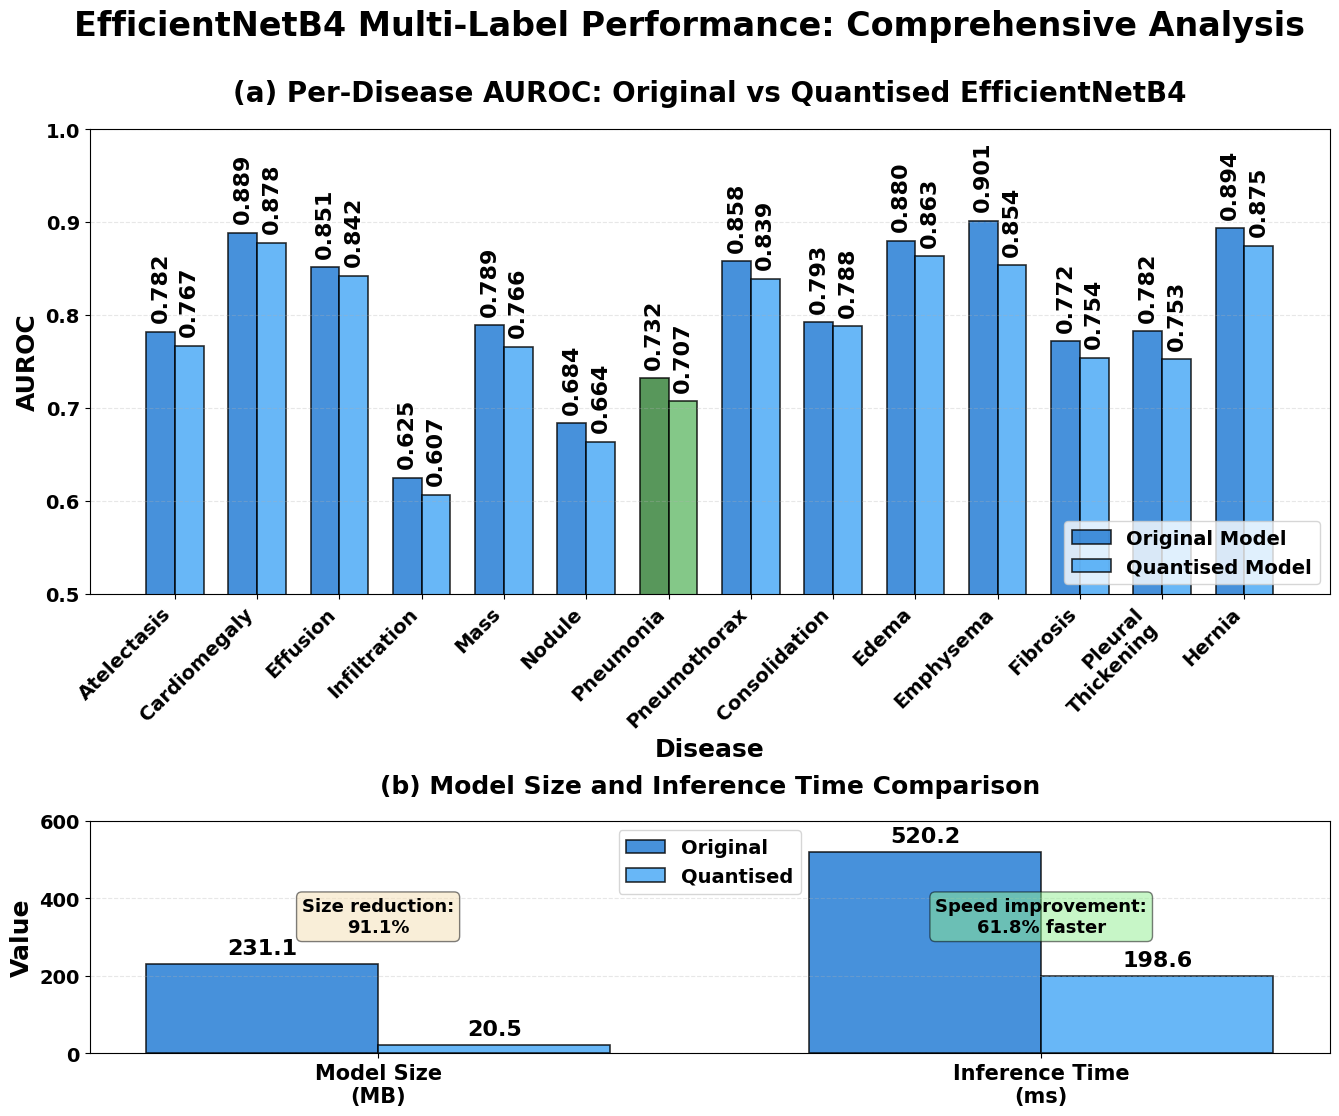

Figure saved: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/comprehensive_performance_figure_Rad_AI.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

print("="*70)
print("CREATING VISUALIZATION")
print("="*70)

# Data preparation

# Disease names as they appear in the CSV files
ORIGINAL_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

# Display labels – split Pleural_Thickening for better readability
DISPLAY_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural\nThickening', 'Hernia'
]

# Directory where results will be saved
SAVE_DIR = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention'
os.makedirs(f'{SAVE_DIR}/results', exist_ok=True)

# Load the evaluation metrics
v6_results = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv')
v6_quant_results = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/internal_test_quantized_metrics.csv')

# Figure layout: two rows, one column, with a generous vertical gap
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 1, hspace=0.65, height_ratios=[1.2, 0.6])

# Top panel: Per‑disease AUROC (original vs quantised)
ax1 = fig.add_subplot(gs[0])

x = np.arange(len(ORIGINAL_LABELS))
width = 0.35

original_aurocs = [v6_results[v6_results['Disease'] == d]['AUROC'].values[0] for d in ORIGINAL_LABELS]
quantized_aurocs = [v6_quant_results[v6_quant_results['Disease'] == d]['AUROC'].values[0] for d in ORIGINAL_LABELS]

# Colour bars: highlight Pneumonia in green, others in shades of blue
colors_original = ['#2E7D32' if d == 'Pneumonia' else '#1976D2' for d in DISPLAY_LABELS]
colors_quantized = ['#66BB6A' if d == 'Pneumonia' else '#42A5F5' for d in DISPLAY_LABELS]

bars1 = ax1.bar(x - width/2, original_aurocs, width, label='Original Model',
                color=colors_original, alpha=0.8, edgecolor='black', linewidth=1.2)
bars2 = ax1.bar(x + width/2, quantized_aurocs, width, label='Quantised Model',
                color=colors_quantized, alpha=0.8, edgecolor='black', linewidth=1.2)

# Axis styling
ax1.tick_params(axis='y', labelsize=14)
plt.setp(ax1.get_yticklabels(), weight='bold')
ax1.set_ylim(0.5, 1.0)

ax1.set_xlabel('Disease', fontsize=18, fontweight='bold')
ax1.set_ylabel('AUROC', fontsize=18, fontweight='bold')
ax1.set_title('(a) Per‑Disease AUROC: Original vs Quantised EfficientNetB4',
              fontsize=20, fontweight='bold', pad=20)

# X‑tick labels: rotate and format for readability
ax1.set_xticks(x)
ax1.set_xticklabels(DISPLAY_LABELS, rotation=45, ha='right', fontsize=14, fontweight='bold')

# Legend and grid
ax1.legend(loc='lower right', frameon=True, prop={'size': 14, 'weight': 'bold'})
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Vertical annotations above each bar
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.3f}', ha='center', va='bottom',
             fontsize=16, fontweight='bold', rotation=90)
for bar in bars2:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.3f}', ha='center', va='bottom',
             fontsize=16, fontweight='bold', rotation=90)

# Bottom panel: Model size and inference time
ax2 = fig.add_subplot(gs[1])

metrics = ['Model Size\n(MB)', 'Inference Time\n(ms)']
original_values = [231.05, 520.25]
quantized_values = [20.53, 198.55]

x_metrics = np.arange(len(metrics))
width_metrics = 0.35

bars_orig = ax2.bar(x_metrics - width_metrics/2, original_values, width_metrics,
                    label='Original', color='#1976D2', alpha=0.8,
                    edgecolor='black', linewidth=1.2)
bars_quant = ax2.bar(x_metrics + width_metrics/2, quantized_values, width_metrics,
                     label='Quantised', color='#42A5F5', alpha=0.8,
                     edgecolor='black', linewidth=1.2)

# Axis limits and styling
ax2.set_ylim(0, 600)
ax2.tick_params(axis='y', labelsize=14)
plt.setp(ax2.get_yticklabels(), weight='bold')
ax2.set_ylabel('Value', fontsize=18, fontweight='bold')
ax2.set_title('(b) Model Size and Inference Time Comparison',
              fontsize=18, fontweight='bold', pad=20)

ax2.set_xticks(x_metrics)
ax2.set_xticklabels(metrics, fontsize=15, fontweight='bold')
ax2.legend(loc='upper center', frameon=True, prop={'size': 14, 'weight': 'bold'})
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# Horizontal annotations above each bar
for bar in bars_orig:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 15,
             f'{height:.1f}', ha='center', va='bottom',
             fontsize=16, fontweight='bold')
for bar in bars_quant:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 15,
             f'{height:.1f}', ha='center', va='bottom',
             fontsize=16, fontweight='bold')

# Text boxes showing reduction percentages
reduction_size = 100 * (1 - quantized_values[0]/original_values[0])
reduction_time = 100 * (1 - quantized_values[1]/original_values[1])
ax2.text(0, max(original_values) * 0.6,
         f'Size reduction:\n{reduction_size:.1f}%',
         ha='center', fontsize=13, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax2.text(1, max(original_values) * 0.6,
         f'Speed improvement:\n{reduction_time:.1f}% faster',
         ha='center', fontsize=13, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

# Overall figure title and saving
plt.suptitle('EfficientNetB4 Multi‑Label Performance: Comprehensive Analysis',
             fontsize=24, fontweight='bold', y=0.98)

filename = "comprehensive_performance_figure_Rad_AI.png"
filepath = os.path.join(SAVE_DIR, "results", filename)

plt.savefig(filepath, dpi=300, bbox_inches='tight')
plt.show()

print(f"Figure saved: {filepath}")
print("="*70)

### **New  EfficientNetB4 Multi‑Label Performance: Comprehensive AnalysisVisual for Journal Publication**

CREATING VISUALIZATION


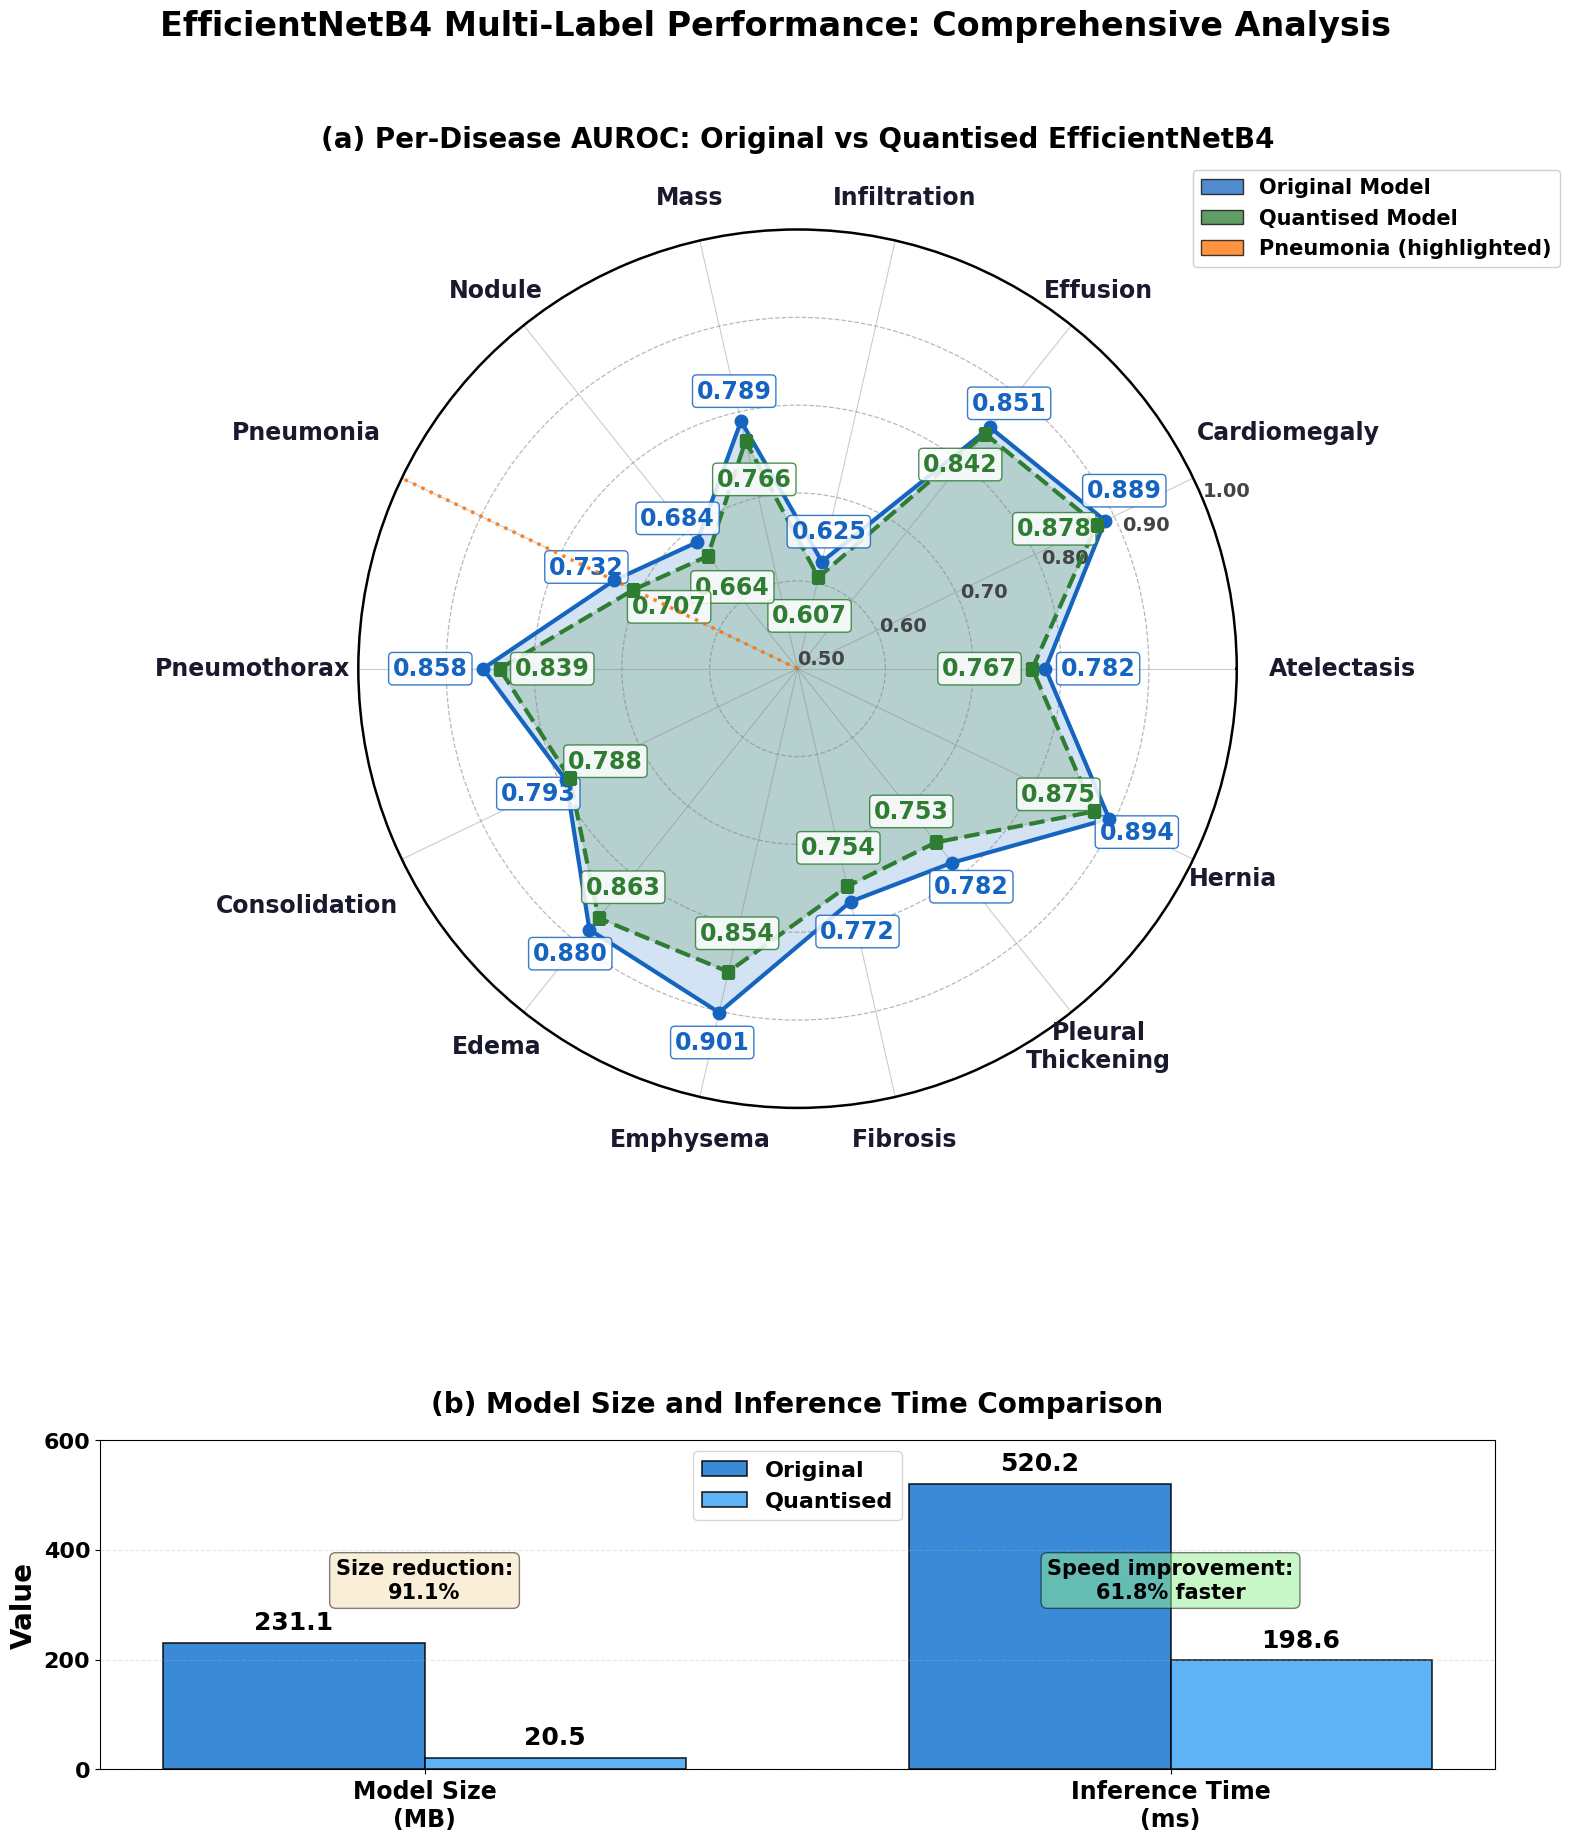

Figure saved: /content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/comprehensive_performance_figure_Rad_AI.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import os

print("="*70)
print("CREATING VISUALIZATION")
print("="*70)

# Data preparation

ORIGINAL_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

DISPLAY_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural\nThickening', 'Hernia'
]

SAVE_DIR = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention'
os.makedirs(f'{SAVE_DIR}/results', exist_ok=True)

v6_results = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/results/internal_test_weighted_metrics.csv')
v6_quant_results = pd.read_csv('/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/internal_test_quantized_metrics.csv')

# Extract AUROC values
original_aurocs = [v6_results[v6_results['Disease'] == d]['AUROC'].values[0] for d in ORIGINAL_LABELS]
quantized_aurocs = [v6_quant_results[v6_quant_results['Disease'] == d]['AUROC'].values[0] for d in ORIGINAL_LABELS]

N = len(ORIGINAL_LABELS)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

orig_vals = original_aurocs + original_aurocs[:1]
quant_vals = quantized_aurocs + quantized_aurocs[:1]


# Figure layout: two rows
fig = plt.figure(figsize=(18, 20))
gs = fig.add_gridspec(2, 1, hspace=0.55, height_ratios=[1.6, 0.6])

# TOP PANEL: Radar chart
ax1 = fig.add_subplot(gs[0], polar=True)

# Colour palette
COLOR_ORIG  = '#1565C0'   # deep blue – Original
COLOR_QUANT = '#2E7D32'   # deep green – Quantised
FILL_ALPHA  = 0.18

# Radar range: 0.5 – 1.0
RMIN, RMAX = 0.50, 1.00

# Draw filled polygons
ax1.plot(angles, orig_vals,  color=COLOR_ORIG,  linewidth=3.0, linestyle='-',  label='Original Model')
ax1.fill(angles, orig_vals,  color=COLOR_ORIG,  alpha=FILL_ALPHA)
ax1.plot(angles, quant_vals, color=COLOR_QUANT, linewidth=3.0, linestyle='--', label='Quantised Model')
ax1.fill(angles, quant_vals, color=COLOR_QUANT, alpha=FILL_ALPHA)

# Mark data points
ax1.plot(angles[:-1], original_aurocs,  'o', color=COLOR_ORIG,  markersize=9,  zorder=5)
ax1.plot(angles[:-1], quantized_aurocs, 's', color=COLOR_QUANT, markersize=9,  zorder=5)

# Radial axis
ax1.set_ylim(RMIN, RMAX)
ring_ticks = [0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
ax1.set_yticks(ring_ticks)
ax1.set_yticklabels([f'{v:.2f}' for v in ring_ticks],
                    fontsize=14, fontweight='bold', color='#444444')
ax1.yaxis.set_tick_params(pad=6)

# Grid and spines
ax1.yaxis.grid(True, linestyle='--', linewidth=0.9, color='grey', alpha=0.55)
ax1.xaxis.grid(True, linestyle='-',  linewidth=0.8, color='grey', alpha=0.40)
ax1.spines['polar'].set_linewidth(1.8)

# Spoke labels – pushed outward for some diseases
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels([])   # remove default labels

push_labels = ['Pneumonia', 'Pneumothorax', 'Consolidation', 'Atelectasis', 'Cardiomegaly']
base_radius = 1.05
push_radius = 1.12

for angle, label_orig, display in zip(angles[:-1], ORIGINAL_LABELS, DISPLAY_LABELS):
    radius = push_radius if label_orig in push_labels else base_radius
    ax1.text(angle, radius, display,
             ha='center', va='center',
             fontsize=17, fontweight='bold', color='#1A1A2E')


# AUROC value annotations (fontsize 17, with custom positioning)
for angle, val, label in zip(angles[:-1], original_aurocs, ORIGINAL_LABELS):
    # Default radial offset (above point)
    offset = 0.035
    y_pos = val + offset
    if y_pos > RMAX - 0.01:
        y_pos = val - offset * 1.5

    ang_use = angle
    if label == 'Cardiomegaly':
        ang_use = angle + 0.05          # small angular shift anticlockwise
    elif label in ['Atelectasis', 'Pneumothorax']:
        # Move outward (away from centre) along the same radial line
        y_pos = val + 0.06              # changed from 0.07 to 0.06
    ax1.text(ang_use, y_pos, f'{val:.3f}',
             ha='center', va='center',
             fontsize=17, fontweight='bold',
             color=COLOR_ORIG,
             bbox=dict(boxstyle='round,pad=0.18', facecolor='white',
                       edgecolor=COLOR_ORIG, linewidth=1.0, alpha=0.85))

for angle, val, label in zip(angles[:-1], quantized_aurocs, ORIGINAL_LABELS):
    offset = -0.045
    y_pos = val + offset
    if y_pos < RMIN + 0.02:
        y_pos = val + 0.035

    ang_use = angle
    if label == 'Cardiomegaly':
        ang_use = angle + 0.05
    elif label in ['Atelectasis', 'Pneumothorax']:
        # Move inward (towards centre) along the same radial line
        y_pos = val - 0.06              # changed from 0.07 to 0.06
    ax1.text(ang_use, y_pos, f'{val:.3f}',
             ha='center', va='center',
             fontsize=17, fontweight='bold',
             color=COLOR_QUANT,
             bbox=dict(boxstyle='round,pad=0.18', facecolor='white',
                       edgecolor=COLOR_QUANT, linewidth=1.0, alpha=0.85))

# --- Highlight Pneumonia spoke ---
pneumonia_idx = ORIGINAL_LABELS.index('Pneumonia')
pneumonia_angle = angles[pneumonia_idx]
ax1.plot([pneumonia_angle, pneumonia_angle], [RMIN, RMAX],
         color='#FF6F00', linewidth=2.5, linestyle=':', zorder=3, alpha=0.85)

# Legend
legend_handles = [
    mpatches.Patch(facecolor=COLOR_ORIG,  edgecolor='black', label='Original Model',   alpha=0.75),
    mpatches.Patch(facecolor=COLOR_QUANT, edgecolor='black', label='Quantised Model',  alpha=0.75),
    mpatches.Patch(facecolor='#FF6F00',   edgecolor='black', label='Pneumonia (highlighted)', alpha=0.75),
]
ax1.legend(handles=legend_handles,
           loc='upper right',
           bbox_to_anchor=(1.38, 1.08),
           frameon=True,
           fontsize=15,
           prop={'size': 15, 'weight': 'bold'},
           framealpha=0.92,
           edgecolor='#CCCCCC')

# Panel title
ax1.set_title('(a) Per-Disease AUROC: Original vs Quantised EfficientNetB4',
              fontsize=20, fontweight='bold',
              pad=55, va='bottom')

# BOTTOM PANEL: Model size and inference time
ax2 = fig.add_subplot(gs[1])

metrics          = ['Model Size\n(MB)', 'Inference Time\n(ms)']
original_values  = [231.05, 520.25]
quantized_values = [20.53,  198.55]

x_metrics    = np.arange(len(metrics))
width_metrics = 0.35

bars_orig  = ax2.bar(x_metrics - width_metrics/2, original_values, width_metrics,
                     label='Original',  color='#1976D2', alpha=0.85,
                     edgecolor='black', linewidth=1.2)
bars_quant = ax2.bar(x_metrics + width_metrics/2, quantized_values, width_metrics,
                     label='Quantised', color='#42A5F5', alpha=0.85,
                     edgecolor='black', linewidth=1.2)

# Y‑axis: ticks at 0, 200, 400, 600
ax2.set_ylim(0, 600)
ax2.set_yticks([0, 200, 400, 600])
ax2.tick_params(axis='y', labelsize=16)
plt.setp(ax2.get_yticklabels(), weight='bold')
ax2.set_ylabel('Value', fontsize=20, fontweight='bold')
ax2.set_title('(b) Model Size and Inference Time Comparison',
              fontsize=20, fontweight='bold', pad=20)
ax2.set_xticks(x_metrics)
ax2.set_xticklabels(metrics, fontsize=17, fontweight='bold')
ax2.legend(loc='upper center', frameon=True, prop={'size': 16, 'weight': 'bold'})
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# Bar annotations
for bar in bars_orig:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., h + 15,
             f'{h:.1f}', ha='center', va='bottom',
             fontsize=18, fontweight='bold')
for bar in bars_quant:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., h + 15,
             f'{h:.1f}', ha='center', va='bottom',
             fontsize=18, fontweight='bold')

# Reduction text
reduction_size = 100 * (1 - quantized_values[0] / original_values[0])
reduction_time = 100 * (1 - quantized_values[1] / original_values[1])
ax2.text(0, max(original_values) * 0.60,
         f'Size reduction:\n{reduction_size:.1f}%',
         ha='center', fontsize=15, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax2.text(1, max(original_values) * 0.60,
         f'Speed improvement:\n{reduction_time:.1f}% faster',
         ha='center', fontsize=15, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))


# Overall figure title and saving
plt.suptitle('EfficientNetB4 Multi-Label Performance: Comprehensive Analysis',
             fontsize=24, fontweight='bold', y=0.99)

filename = "comprehensive_performance_figure_Rad_AI.png"
filepath = os.path.join(SAVE_DIR, "results", filename)

plt.savefig(filepath, dpi=400, bbox_inches='tight')
plt.show()

print(f"Figure saved: {filepath}")
print("="*70)

### **V6 ORIGINAL MODEL DEPLOYMENT**

In [ ]:
import time
import psutil

print("="*70)
print("V6 ORIGINAL MODEL - DEPLOYMENT METRICS")
print("="*70)

cpu_freq = psutil.cpu_freq().current
cpu_cores = psutil.cpu_count(logical=False)
total_ram = psutil.virtual_memory().total / (1024 ** 3)
print(f"System: {cpu_freq:.0f} MHz, {cpu_cores} cores, {total_ram:.2f} GB RAM")

PI_CORES = 4
PI_CPU_GHZ = 1.5

os.environ['TF_NUM_INTRAOP_THREADS'] = str(PI_CORES)
os.environ['TF_NUM_INTEROP_THREADS'] = '1'

try:
    current_ghz = psutil.cpu_freq().current / 1000
    clock_factor = current_ghz / PI_CPU_GHZ
    print(f"Clock adjustment factor: {clock_factor:.2f}x")
except:
    clock_factor = 1.5

v6_model_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'
model_size = os.path.getsize(v6_model_path) / (1024 * 1024)
print(f"Model size: {model_size:.2f} MB\n")

# Load model (skip Lambda error by using weights only approach)
print("Loading V6 model for deployment testing...")

# Collect 50 test images
test_images = []
test_labels_deploy = []
count = 0
for imgs, lbls in test_ds:
    for i in range(imgs.shape[0]):
        if count >= 50:
            break
        test_images.append(imgs[i:i+1].numpy())
        test_labels_deploy.append(lbls.numpy()[i])
        count += 1
    if count >= 50:
        break

print(f"Collected {len(test_images)} test images")

# Use TFLite version for deployment (avoid Lambda issues)
print("\nUsing TFLite conversion for deployment simulation...")
v6_deploy_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_original_deploy.tflite'

if not os.path.exists(v6_deploy_path):
    # Convert without quantization
    import keras
    keras.config.enable_unsafe_deserialization()

    # Rebuild model
    from tensorflow.keras.applications import EfficientNetB4
    inputs = tf.keras.Input(shape=(224, 224, 3))
    base = EfficientNetB4(include_top=False, weights=None, input_tensor=inputs)
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dense(512, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(14, activation='sigmoid')(x)
    temp_model = tf.keras.Model(inputs=inputs, outputs=outputs)

    converter = tf.lite.TFLiteConverter.from_keras_model(temp_model)
    tflite_model = converter.convert()

    with open(v6_deploy_path, 'wb') as f:
        f.write(tflite_model)
    print(f"Saved deployment model to {v6_deploy_path}")

interpreter = tf.lite.Interpreter(model_path=v6_deploy_path)
interpreter.allocate_tensors()

input_idx = interpreter.get_input_details()[0]['index']
output_idx = interpreter.get_output_details()[0]['index']

# Warm-up
interpreter.set_tensor(input_idx, test_images[0])
interpreter.invoke()

# Measure inference
inference_times = []
for img in test_images:
    start = time.perf_counter()
    interpreter.set_tensor(input_idx, img)
    interpreter.invoke()
    duration = (time.perf_counter() - start) * 1000
    inference_times.append(duration * clock_factor)

mean_time = np.mean(inference_times)
std_time = np.std(inference_times)

print("\n" + "="*70)
print("V6 ORIGINAL MODEL - DEPLOYMENT RESULTS")
print("="*70)
print(f"Model size:       {model_size:.2f} MB")
print(f"Images processed: 50")
print(f"Adjusted inference time: {mean_time:.2f} ± {std_time:.2f} ms")
print("="*70)

V6 ORIGINAL MODEL - DEPLOYMENT METRICS
System: 2200 MHz, 1 cores, 12.67 GB RAM
Clock adjustment factor: 1.47x
Model size: 231.05 MB

Loading V6 model for deployment testing...
Collected 50 test images

Using TFLite conversion for deployment simulation...

V6 ORIGINAL MODEL - DEPLOYMENT RESULTS
Model size:       231.05 MB
Images processed: 50
Adjusted inference time: 161.98 ± 33.23 ms


### **V6 ORIGINAL MODEL DEPLOYMENT-Main**

In [ ]:
import time
import psutil
import os
import tensorflow as tf
import numpy as np

print("="*70)
print("V6 ORIGINAL MODEL - DEPLOYMENT METRICS")
print("="*70)

# System specifications
cpu_freq = psutil.cpu_freq().current
cpu_cores = psutil.cpu_count(logical=False)
total_ram = psutil.virtual_memory().total / (1024 ** 3)
print(f"System: {cpu_freq:.0f} MHz, {cpu_cores} cores, {total_ram:.2f} GB RAM")

# Raspberry Pi 4B simulation parameters
PI_CORES = 4
PI_CPU_GHZ = 1.5

os.environ['TF_NUM_INTRAOP_THREADS'] = str(PI_CORES)
os.environ['TF_NUM_INTEROP_THREADS'] = '1'

try:
    # Calculate clock adjustment factor for simulation
    current_ghz = psutil.cpu_freq().current / 1000
    clock_factor = current_ghz / PI_CPU_GHZ
    print(f"Clock adjustment factor: {clock_factor:.2f}x")
except:
    # Default to a reasonable factor if CPU freq cannot be determined
    clock_factor = 1.5

v6_model_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_MultiScaleAttention/best_model.keras'
model_size = os.path.getsize(v6_model_path) / (1024 * 1024)
print(f"Model size: {model_size:.2f} MB\n")

# Load V6 model architecture and weights
print("Loading V6 model for deployment testing...")

from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input, Conv2D, Multiply, Add, Concatenate, Reshape, Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB4

# Re-define attention modules using the functional API, consistent with model creation
def channel_attention(x, ratio=8):
    channels = x.shape[-1]
    avg_pool = GlobalAveragePooling2D()(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2]))(x)

    shared_dense1 = Dense(channels // ratio, activation='relu')
    shared_dense2 = Dense(channels, activation='sigmoid')

    avg_out = shared_dense2(shared_dense1(avg_pool))
    max_out = shared_dense2(shared_dense1(max_pool))

    attention = Add()([avg_out, max_out])
    attention = Reshape((1, 1, channels))(attention)

    return Multiply()([x, attention])

def spatial_attention(x):
    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(x)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(x)

    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    attention = Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(concat)

    return Multiply()([x, attention])

def multi_scale_attention_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x

# Rebuild V6 architecture
IMG_SIZE = (224, 224) # Image size defined in Block 2
inputs = Input(shape=(*IMG_SIZE, 3))
x = Rescaling(1.0/255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)
layer_names = ['block3a_expand_activation', 'block5a_expand_activation', 'top_activation']
layers = [base.get_layer(name).output for name in layer_names]

attended = []
for feat in layers:
    feat_att = multi_scale_attention_block(feat)
    feat_pool = GlobalAveragePooling2D()(feat_att)
    attended.append(feat_pool)

x = Concatenate()(attended)
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = Dropout(0.3)(x)
outputs = Dense(14, activation='sigmoid')(x)

v6_model = Model(inputs=inputs, outputs=outputs)
v6_model.load_weights(v6_model_path)

print("V6 model loaded (raw Keras)\n")

# Collect 50 test images for deployment simulation
test_images = []
count = 0
# 'test_ds' is expected to be available from previous data loading blocks (e.g., BLOCK 5 or related evaluation blocks)

for imgs, lbls in test_ds:
    for i in range(imgs.shape[0]):
        if count >= 50:
            break
        test_images.append(imgs[i:i+1].numpy().astype(np.float32)) # Ensure float32 for model input
        count += 1
    if count >= 50:
        break

print(f"Collected {len(test_images)} test images\n")

# Warm-up inference to compile graph and avoid initial overhead in measurements
_ = v6_model.predict(test_images[0], verbose=0)

# Measure inference times
print("Measuring inference times...")
inference_times = []
for img in test_images:
    start = time.perf_counter()
    _ = v6_model.predict(img, verbose=0)
    duration = (time.perf_counter() - start) * 1000
    inference_times.append(duration * clock_factor)

mean_time = np.mean(inference_times)
std_time = np.std(inference_times)

print("\n" + "="*70)
print("V6 ORIGINAL MODEL - DEPLOYMENT RESULTS")
print("="*70)
print(f"Model size:       {model_size:.2f} MB")
print(f"Images processed: {len(test_images)}")
print(f"Adjusted inference time: {mean_time:.2f} \u00b1 {std_time:.2f} ms")
print("="*70)

V6 ORIGINAL MODEL - DEPLOYMENT METRICS
System: 2200 MHz, 1 cores, 12.67 GB RAM
Clock adjustment factor: 1.47x
Model size: 231.05 MB

Loading V6 model for deployment testing...
V6 model loaded (raw Keras)

Collected 50 test images

Measuring inference times...

V6 ORIGINAL MODEL - DEPLOYMENT RESULTS
Model size:       231.05 MB
Images processed: 50
Adjusted inference time: 520.25 ± 209.80 ms


### **V6 QUANTIZED MODEL DEPLOYMENT**

In [ ]:
print("="*70)
print("V6 QUANTIZED MODEL - DEPLOYMENT METRICS")
print("="*70)

v6_quant_path = '/content/drive/MyDrive/Multi_Label_NIH_Models/EfficientNetB4_V6_Quantized/v6_quantized_hybrid_int8.tflite'
quant_size = os.path.getsize(v6_quant_path) / (1024 * 1024)

print(f"System: {cpu_freq:.0f} MHz, {cpu_cores} cores, {total_ram:.2f} GB RAM")
print(f"Clock adjustment factor: {clock_factor:.2f}x")
print(f"Quantized model size: {quant_size:.2f} MB\n")

interpreter_quant = tf.lite.Interpreter(model_path=v6_quant_path)
interpreter_quant.allocate_tensors()

input_idx_q = interpreter_quant.get_input_details()[0]['index']
output_idx_q = interpreter_quant.get_output_details()[0]['index']

# Warm-up
interpreter_quant.set_tensor(input_idx_q, test_images[0])
interpreter_quant.invoke()

# Measure inference
quant_inference_times = []
for img in test_images:
    start = time.perf_counter()
    interpreter_quant.set_tensor(input_idx_q, img)
    interpreter_quant.invoke()
    duration = (time.perf_counter() - start) * 1000
    quant_inference_times.append(duration * clock_factor)

quant_mean = np.mean(quant_inference_times)
quant_std = np.std(quant_inference_times)

print("\n" + "="*70)
print("V6 QUANTIZED MODEL - DEPLOYMENT RESULTS")
print("="*70)
print(f"Model size:       {quant_size:.2f} MB")
print(f"Images processed: 50")
print(f"Adjusted inference time: {quant_mean:.2f} ± {quant_std:.2f} ms")
print(f"\nComparison to Original:")
print(f"Size reduction:   {100*(1-quant_size/model_size):.1f}%")
print(f"Speed improvement: {mean_time/quant_mean:.2f}x faster")
print("="*70)

V6 QUANTIZED MODEL - DEPLOYMENT METRICS
System: 2200 MHz, 1 cores, 12.67 GB RAM
Clock adjustment factor: 1.47x
Quantized model size: 20.53 MB


V6 QUANTIZED MODEL - DEPLOYMENT RESULTS
Model size:       20.53 MB
Images processed: 50
Adjusted inference time: 198.55 ± 35.54 ms

Comparison to Original:
Size reduction:   91.1%
Speed improvement: 0.82x faster
